# Panel de la Épica 2: cómo han quedado los datos tras el preprocesado

**MIAX-214.** Este notebook enseña, con datos reales de la caché, qué hace cada paso de preprocesado de la Épica 2 (tickets MIAX-033 a 046 y 213) y cómo han quedado los 35 paneles trimestrales que recibe la Épica 3. Está escrito para quien no ha visto cada ticket: cada técnica lleva su problema, su idea, la decisión (D-xx, en `docs/project/ESTADO.md` §2) y un ejemplo pequeño.

> **Aviso importante.** Todo lo que se mide aquí es **descriptivo del periodo completo** de cada trimestre (medias, cuantiles, correlaciones, causas de hueco). No son features ni filtros, y no deben alimentar ningún modelo: usarían información del futuro de cada trimestre. Además, **antes de 2021T2 el universo tiene pocas monedas (de 2 a 21)**, así que las cifras de 2018-2021T1 son mucho menos representativas que las de 2021T2 en adelante (40 monedas por trimestre, salvo excepciones).

## 0. Cómo ejecutarlo

- **Requisito:** la caché de velas de 1 minuto en `data/raw/klines` (se obtiene con `python -m miax.ingest sync`, o descomprimiendo el zip del Drive en la raíz del repo). El notebook no toca la red.
- **Primera vez:** si falta algún panel en `data/processed/panel/1m/`, la celda de resumen (sección 0) lo **construye** (unos 10 s por trimestre, unos 6 minutos en total) y lo guarda. Las siguientes veces solo los lee.
- **Con la caché de paneles ya hecha** el notebook entero tarda unos 2-3 minutos (en las pruebas, entre 110 y 180 s); el tiempo del resumen de los 35 paneles se imprime en la celda de resumen.
- **Lógica reutilizable:** vive en `src/` (en concreto `miax.viz.panel_overview` para las tablas por trimestre). El notebook solo llama a esas funciones y dibuja.
- Desde la raíz del repo: `jupyter execute --inplace notebooks/01-eda/01-panel-epica-2.ipynb` (usa `nbclient`, que está en `requirements.txt`), o abrirlo en VS Code o Jupyter con el kernel del `.venv`.

In [1]:
# Imports y ajustes generales. Todo el cálculo viene de miax.*; aquí solo se llama y se dibuja.
import io
import json
import logging
import time
import warnings
from dataclasses import asdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from miax.features import (
    FEATURE_SPECS,
    GapCause,
    Panel,
    align_klines,
    build_panel,
    build_time_grid,
    cached_panel,
    cause_counts,
    classify_klines,
    clip_returns,
    fit_clip_bounds,
    gap_runs,
    horizon_returns_from_cache,
    load_panel,
    panel_path,
    resample_from_cache,
    resample_validity,
    returns_from_cache,
    shift_to_close,
    tail_report,
    validate_panel,
    validity_mask,
)
from miax.ingest.store import DEFAULT_BASE_DIR
from miax.ingest.universe import load_universe, to_ms
from miax.utils.io import resolve_repo_path
from miax.viz import (
    bar_validity_pct,
    build_panel_overview,
    order_by_category,
    plot_raw_correlation,
    raw_correlation,
    summarize_correlation,
    symbols_without_data,
)

# Sin el log INFO de miax (cada panel que se carga escribe una línea), pero con sus avisos: así se ve,
# por ejemplo, la moneda sin datos que se aparta de la correlación. Cada módulo tiene su propio logger
# con nivel INFO, así que se baja el de todos los que empiezan por "miax".
for logger_name in list(logging.root.manager.loggerDict):
    if logger_name.startswith("miax"):
        logging.getLogger(logger_name).setLevel(logging.WARNING)

# Tablas legibles y figuras con resolución moderada (el .ipynb pesa unos pocos MB con las salidas).
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 5)
plt.rcParams.update(
    {
        "figure.dpi": 80,
        "savefig.dpi": 80,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

REPO = resolve_repo_path(".")  # raíz del repositorio (para mostrar rutas relativas, no absolutas)
universe = load_universe()  # universo trimestral (D-25): una fila por moneda y trimestre


def ms(text):
    # Fecha en texto -> milisegundos UTC, que es lo que piden las funciones de miax.
    return to_ms(pd.Timestamp(text, tz="UTC"))


def period_info(start_text):
    # Símbolos, inicio y fin (en ms) del trimestre que empieza en `start_text`.
    rows = universe[universe["period_start"] == pd.Timestamp(start_text, tz="UTC")]
    return (
        list(rows["symbol"]),
        to_ms(rows["period_start"].iloc[0]),
        to_ms(rows["period_end"].iloc[0]),
    )


def read_panel(start_text, features=None, symbols=None):
    # Lee un panel ya guardado en la caché (solo las features y símbolos pedidos).
    _, start, end = period_info(start_text)
    return load_panel(panel_path("1m", start, end), features=features, symbols=symbols)


def qlabel(moment):
    # 2025-07-01 -> "2025T3"
    return f"{moment.year}T{(moment.month - 1) // 3 + 1}"


def plain(symbol):
    # Etiqueta corta de un símbolo para los ejes: sin USDT, y sin caracteres chinos (la fuente no los dibuja).
    return symbol.removesuffix("USDT") if symbol.isascii() else "(CJK)"


def show(fig):
    # Muestra una figura de matplotlib creada sin pyplot (la de plot_raw_correlation).
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=80)
    display(Image(data=buffer.getvalue()))


print("Caché de velas:", DEFAULT_BASE_DIR)
print(
    "Trimestres en el universo:",
    universe["period_start"].nunique(),
    "| monedas distintas:",
    universe["symbol"].nunique(),
)

Caché de velas: data/raw/klines
Trimestres en el universo: 35 | monedas distintas: 146


### Carga del resumen de los 35 paneles

La celda siguiente recorre los paneles de la caché **una sola vez** (`miax.viz.build_panel_overview`) y deja en `overview` todas las tablas que se usan de la sección 3 a la 8: calidad por moneda y trimestre, cuantiles de las features, colas de los retornos, validez de las barras de 5/15/60 minutos, causas de hueco, resumen de correlación y resultado del contrato. Si un panel no está en la caché, lo construye y lo guarda (es la parte lenta de la primera ejecución).

In [2]:
# Resumen de los 35 paneles: se carga cada panel una sola vez y se calculan todas las tablas.
t0 = time.time()
overview = build_panel_overview(universe, "1m")
elapsed = time.time() - t0

print(f"Resumen de {len(overview.periods)} paneles en {elapsed:.0f} s")
for name in overview._fields:
    table = getattr(overview, name)
    print(f"  {name:18s} {table.shape[0]:6d} filas x {table.shape[1]:2d} columnas")

2026-11-02T19:25:45Z | WARNING | miax.viz.raw_correlation | Periodo 2024-07-01: 1 simbolos sin datos, fuera del resumen y de los componentes: AGIXUSDT


2026-11-02T19:26:27Z | WARNING | miax.viz.raw_correlation | Periodo 2026-07-01: 1 simbolos sin datos, fuera del resumen y de los componentes: TONUSDT


2026-11-02T19:26:28Z | WARNING | miax.features.alignment | Sin velas de TONUSDT 1m en el rango: columna de NaN


Resumen de 35 paneles en 123 s
  periods                35 filas x  5 columnas
  quality               996 filas x  5 columnas
  feature_quantiles     140 filas x  7 columnas
  tails                 996 filas x  9 columnas
  bar_validity          996 filas x  4 columnas
  gap_causes            996 filas x  7 columnas
  correlation            35 filas x 26 columnas


**Interpretación.** Con la caché de paneles ya construida, el resumen de los 35 trimestres tarda un par de minutos (el tiempo exacto se imprime arriba). Las tablas por moneda y trimestre tienen **996 filas**, que es exactamente el tamaño del universo trimestral (996 pares-trimestre de 146 monedas distintas), y las tablas por trimestre tienen 35 filas. Todo lo que se ve de la sección 3 a la 8 sale de estas siete tablas, así que las cifras son coherentes entre sí.

## 1. La cadena de la Épica 2

Cada ticket añade un eslabón. El resultado final es el **panel** (`miax.features.Panel`): cuatro features por minuto y por moneda más una máscara de validez, un panel por trimestre del universo.

```text
 velas de 1 minuto (Binance, caché Parquet en data/raw/klines)
        │
        ▼  033  rejilla común UTC: un slot por minuto y moneda; lo que falta es NaN
 ┌────────────────┐
 │ precios y      │   (D-16)
 │ volúmenes en   │
 │ rejilla común  │
 └──────┬─────────┘
        ▼  034  causa de cada hueco (ex post, solo descriptiva)        (D-17)
        ▼  035  máscara de validez: válido = hay vela con operaciones   (D-02, D-18)
        ▼  036  retorno log a 1 paso, indexado al CIERRE de la vela      (D-19)
        ▼  037  colas: se miden, NO se recortan por defecto             (D-22)
        ▼  038  volatilidad realizada reescalada por los retornos que faltan (D-20)
        ▼  039/040  volumen y operaciones relativos a los 7 días anteriores  (D-21)
        ▼  041  panel por trimestre: 4 features + valid, to_array (T, N, F)  (D-24)
        ▼  042  barras de 5/15/60 min desde 1 min, regla del 80 %       (D-23)
        ▼  043  caché Parquet del panel, un directorio por trimestre    (D-26)
        ▼  044  contrato A → B y validate_panel automático             (D-29)
        ▼  045  red de tests de huecos (mundo sintético con oráculo)
        ▼  046/213  correlación cruda del periodo (la foto del «antes») (D-30)
        │
        ▼
 PANEL por trimestre ──► Épica 3 (residualización y lead-lag)
```

**Qué recibe la Épica 3:** por cada trimestre del universo, un `Panel` con `return`, `realized_vol`, `rel_volume`, `rel_trades` (todas `float64`, `tiempo × moneda`) y `valid` (`bool`). Lo que falta es `NaN`, nunca 0. La fila `τ` es lo que se sabía en el instante `τ`. Las columnas cambian de un trimestre a otro. El contrato completo está en `docs/datos/contrato-a-b.md`.

## 2. Las técnicas, una a una, con un ejemplo real

Cada subsección explica **qué problema resuelve** la técnica, **qué se hace**, la **decisión** que la fija y el **ticket**, y termina con un ejemplo pequeño calculado con las funciones de `src/` sobre la caché local.

### 2.1 Rejilla común UTC (MIAX-033, D-16)

**Problema.** Cada moneda tiene sus propias velas y no todas existen a la vez: las monedas nacen, se paran y se deslistan. Para comparar dos monedas hace falta que **cada fila sea el mismo minuto para todas**.

**Qué se hace.** `build_time_grid` crea la lista de minutos de un rango (aperturas de vela en `[inicio, fin)`, en UTC, sin frecuencia fija porque habrá huecos) y `align_klines` coloca cada vela en su slot. Lo que no existe queda `NaN`: nunca se inventa un dato.

**Ejemplo.** El 13 de mayo de 2022 a las 00:40 UTC Binance dejó de servir velas de `LUNAUSDT`. Se ven ocho minutos de `BTCUSDT` y `LUNAUSDT`.

In [3]:
# Rejilla de 8 minutos alrededor del momento en que LUNAUSDT deja de tener velas.
start, end = ms("2022-05-13 00:36"), ms("2022-05-13 00:44")
grid = build_time_grid(start, end, "1m")
print("slots:", len(grid), "| dtype del índice:", grid.dtype, "| freq:", grid.freq)

# Un DataFrame por campo (tiempo x moneda). LUNAUSDT queda en NaN desde las 00:40.
aligned = align_klines(["BTCUSDT", "LUNAUSDT"], "1m", start, end, fields=("close", "num_trades"))
display(pd.concat(aligned, axis=1))

slots: 8 | dtype del índice: datetime64[ms, UTC] | freq: None


close          num_trades         
                            BTCUSDT LUNAUSDT    BTCUSDT LUNAUSDT
2022-05-13 00:36:00+00:00  29183.70  0.00005     1236.0   3933.0
2022-05-13 00:37:00+00:00  29233.33  0.00004     1301.0   4329.0
2022-05-13 00:38:00+00:00  29219.92  0.00006     1500.0   4493.0
2022-05-13 00:39:00+00:00  29200.02  0.00005      709.0   4467.0
2022-05-13 00:40:00+00:00  29201.20      NaN     1039.0      NaN
2022-05-13 00:41:00+00:00  29258.32      NaN     1124.0      NaN
2022-05-13 00:42:00+00:00  29288.57      NaN     1757.0      NaN
2022-05-13 00:43:00+00:00  29384.23      NaN     1824.0      NaN

**Interpretación.** Las dos monedas comparten exactamente las mismas 8 filas, con índice `datetime64[ms, UTC]` y sin frecuencia fija (`freq: None`). `BTCUSDT` tiene vela en los 8 minutos. `LUNAUSDT` tiene velas hasta las 00:39 (entre 3 933 y 4 493 operaciones por minuto) y desde las 00:40 queda en `NaN` tanto en `close` como en `num_trades`: no se arrastra el último precio (0,00005) ni se pone un 0. Es el comienzo de la parada de 18 días que se mide en 2.2.

### 2.2 Causas de los huecos (MIAX-034, D-17)

**Problema.** Un `NaN` puede significar cosas muy distintas: la moneda aún no cotizaba, Binance paró el par un tiempo, Binance entero se cayó, la moneda se deslistó, o simplemente nadie operó ese minuto. Para limpiar y para la memoria conviene distinguirlas.

**Qué se hace.** `classify_klines` etiqueta cada slot con una de siete causas (`GapCause`): `VALID` (hay vela con operaciones), `NO_TRADES` (hay vela pero con 0 operaciones), `NOT_LISTED` (antes de existir), `HALTED` (parada con vuelta posterior), `OUTAGE` (caída que afecta a varias monedas a la vez), `DELISTED` (después de la última vela) y `NO_DATA` (sin información). `cause_counts` las cuenta y `gap_runs` lista los tramos seguidos.

**Decisión D-17: la etiqueta es *ex post*.** Distinguir una parada (`HALTED`) de un deslistado (`DELISTED`) exige saber si la serie *vuelve*, es decir, mirar al futuro. Por eso la causa sirve para limpiar y para la memoria, **nunca como feature**: lo único que se sabe en el instante `t` es si hay una observación buena (`VALID`), y eso es lo que usa la máscara de validez. El panel guarda `valid`, no la causa.

**Ejemplo 1.** `LUNAUSDT` en 2022T2 (la caída de Terra).

In [4]:
# Causas de hueco de LUNAUSDT (y BTCUSDT como referencia sana) en 2022T2.
causes = classify_klines(["BTCUSDT", "LUNAUSDT"], "1m", ms("2022-04-01"), ms("2022-07-01"))
display(cause_counts(causes))

runs = gap_runs(causes)  # tramos consecutivos sin VALID
runs["duración (días)"] = runs["n_slots"] / 1440
display(runs)

,VALID,NO_TRADES,NOT_LISTED,HALTED,OUTAGE,DELISTED,NO_DATA
symbol,,,,,,,
BTCUSDT,131040,0,0,0,0,0,0
LUNAUSDT,104799,1,0,26240,0,0,0


,symbol,cause,start,end,n_slots,duración (días)
0,LUNAUSDT,HALTED,2022-05-13 00:40:00+00:00,2022-05-31 05:59:00+00:00,26240,18.22222
1,LUNAUSDT,NO_TRADES,2022-06-25 03:39:00+00:00,2022-06-25 03:39:00+00:00,1,0.00069


**Interpretación.** `BTCUSDT` no tiene ningún hueco en el trimestre: sus 131 040 minutos (91 días) son `VALID`. `LUNAUSDT` tiene 104 799 minutos válidos, 1 sin operaciones (25-jun, 03:39) y **26 240 `HALTED`**: un único tramo del 13-may 00:40 al 31-may 05:59, es decir, **18,2 días**. Se etiqueta `HALTED` y no `DELISTED` porque la serie *vuelve* (el mismo símbolo pasa a ser la Terra 2.0, según `docs/datos/sesgo-supervivencia.md`), y eso es una información del futuro: por eso es ex post y no entra en el panel (D-17). Este tramo es el 20 % de minutos sin validez que se ve para LUNA en 2022T2 (79,97 % válido, sección 4).

**Ejemplo 2.** Una caída de Binance (`OUTAGE`) solo se distingue cuando faltan varias monedas a la vez. Se piden los cinco tramos más largos de `BTCUSDT` en 2018T1 (cuando el universo solo tenía dos monedas) y salen los 4 que hay.

In [5]:
# Con solo 2 monedas (BTC y ETH), un hueco simultáneo de ambas se etiqueta OUTAGE.
causes_2018 = classify_klines(["BTCUSDT", "ETHUSDT"], "1m", ms("2018-01-01"), ms("2018-04-01"))
runs_2018 = gap_runs(causes_2018)
top = runs_2018[runs_2018["symbol"] == "BTCUSDT"].nlargest(5, "n_slots").copy()
top["duración (horas)"] = top["n_slots"] / 60
display(top)

,symbol,cause,start,end,n_slots,duración (horas)
1,BTCUSDT,OUTAGE,2018-02-08 00:29:00+00:00,2018-02-09 09:59:00+00:00,2011,33.51667
0,BTCUSDT,OUTAGE,2018-01-04 03:01:00+00:00,2018-01-04 05:05:00+00:00,125,2.08333
3,BTCUSDT,OUTAGE,2018-02-11 04:01:00+00:00,2018-02-11 04:34:00+00:00,34,0.56667
2,BTCUSDT,OUTAGE,2018-02-10 06:00:00+00:00,2018-02-10 06:14:00+00:00,15,0.25000


**Interpretación.** En 2018T1 solo BTC y ETH pasan el filtro del universo. El tramo más largo es del 8 al 9 de febrero: **2 011 minutos (33,5 horas)** sin velas en las dos a la vez, etiquetado `OUTAGE`; hay además uno de 2,1 horas el 4 de enero y dos cortos (34 y 15 minutos). Sumados son 2 185 minutos, el 1,69 % del trimestre, que es justo lo que le falta a BTC para tener el 100 % (98,31 % válido). Que falten **las dos a la vez** es lo que distingue una caída de Binance de un problema de una moneda concreta; con más monedas la regla pide que falte al menos la mitad de las que están vivas y como mínimo dos.

### 2.3 Máscara de validez y por qué NO se rellena con ceros (MIAX-035, D-02 y D-18)

**Problema.** Si un minuto no tiene datos, la tentación es poner un retorno 0 («no se movió»). Eso es falso y además **inyecta autocorrelación**: un tramo de ceros seguido de un salto parece una reacción tardía a lo que hizo BTC, es decir, un falso positivo de lead-lag. Pasa algo parecido con los minutos *sin operaciones*: Binance repite el cierre anterior en esa vela, y ese precio no es una observación nueva.

**Qué se hace.** Un slot es **válido** si y solo si su causa es `VALID` (hay vela con `num_trades > 0`). Un retorno a 1 paso solo es válido si lo son el slot `t` y el `t-1`; **no se puentea un hueco** calculando el retorno desde el último precio válido. Todo lo inválido es `NaN`, nunca 0. A cambio, un slot inválido invalida su retorno y el siguiente (coste asumido).

**Matiz.** Un retorno exactamente 0 **con operaciones** sí se conserva: descartarlo sería filtrar por el valor de la variable que se quiere explicar.

**Ejemplo.** `WLFIUSDT` el 9 de julio de 2026 (una moneda con muchos minutos sin operaciones). La tabla muestra, por vela, su cierre, sus operaciones, su causa, su validez y el retorno resultante.

In [6]:
# Doce minutos de WLFIUSDT en los que hay minutos sin operaciones (NO_TRADES).
sym = ["WLFIUSDT"]
w_start, w_end = ms("2026-07-09 17:44"), ms("2026-07-09 17:56")
raw = align_klines(sym, "1m", w_start, w_end, fields=("close", "num_trades"))
causes_w = classify_klines(sym, "1m", w_start, w_end)
valid_w = validity_mask(causes_w)

# Retornos conocidos en [17:45, 17:57): la fila t + 1 min es el retorno de la vela abierta en t (D-19).
returns_w = returns_from_cache(sym, "1m", w_start + 60_000, w_end + 60_000)

table = pd.DataFrame(
    {
        "close": raw["close"]["WLFIUSDT"],
        "num_trades": raw["num_trades"]["WLFIUSDT"],
        "causa": causes_w["WLFIUSDT"].map(lambda value: GapCause(int(value)).name),
        "válido": valid_w["WLFIUSDT"],
    }
)
table.index.name = "vela abierta a las"
table["retorno (fila t+1 min)"] = (
    returns_w["WLFIUSDT"].reindex(shift_to_close(table.index, "1m")).to_numpy()
)
display(table)

,close,num_trades,causa,válido,retorno (fila t+1 min)
vela abierta a las,,,,,
2026-07-09 17:44:00+00:00,0.0581,1.0,VALID,True,NaN
2026-07-09 17:45:00+00:00,0.0581,0.0,NO_TRADES,False,NaN
2026-07-09 17:46:00+00:00,0.0582,23.0,VALID,True,NaN
2026-07-09 17:47:00+00:00,0.0582,0.0,NO_TRADES,False,NaN
2026-07-09 17:48:00+00:00,0.0582,0.0,NO_TRADES,False,NaN
2026-07-09 17:49:00+00:00,0.0582,0.0,NO_TRADES,False,NaN
2026-07-09 17:50:00+00:00,0.0582,16.0,VALID,True,NaN
2026-07-09 17:51:00+00:00,0.0582,1.0,VALID,True,0.00000
2026-07-09 17:52:00+00:00,0.0583,1.0,VALID,True,0.00172


**Interpretación.** Cada fila es una vela (abierta a la hora de la izquierda); su retorno se conoce un minuto más tarde. Los minutos 17:45, 17:47-17:49 y 17:53-17:54 no tienen operaciones (`num_trades = 0`): Binance repite el cierre anterior (tras el minuto válido de las 17:46, el 0,0582 se repite en los tres minutos 17:47-17:49), pero ese precio no es una observación nueva, así que son `NO_TRADES` e inválidos. Tres consecuencias que se ven en la última columna:

1. **Solo hay retorno cuando la vela y la anterior son válidas.** 17:51 da `0,00000` (17:50 y 17:51 válidas, precio igual) y 17:52 da `0,00172` (de 0,0582 a 0,0583).
2. **Cada minuto sin operaciones deja sin retorno dos filas**: la suya y la siguiente. La vela 17:46 es válida pero su retorno es `NaN` porque la anterior (17:45) no lo es; lo mismo pasa con 17:50 y con 17:55. Es el coste asumido de D-18 a cambio de no puentear huecos.
3. **Ningún `NaN` se ha convertido en 0.** El `0,00000` de 17:51 es un retorno real (precio sin cambio con operaciones), no un relleno.

In [7]:
# ¿Cuántos retornos exactamente 0 hay? Se conservan: son datos reales (precio que no cambia con operaciones).
wlfi = read_panel("2026-07-01", features=["return"], symbols=["WLFIUSDT"]).features["return"][
    "WLFIUSDT"
]
n_rows, n_valid, n_zero = len(wlfi), int(wlfi.notna().sum()), int((wlfi == 0).sum())
print(
    f"Filas del trimestre: {n_rows} | retornos válidos: {n_valid} ({n_valid / n_rows:.1%}) | NaN: {n_rows - n_valid}"
)
print(
    f"Retornos exactamente 0 con operaciones (se conservan): {n_zero} ({n_zero / n_valid:.1%} de los válidos)"
)
# Si se hubiera hecho fillna(0), los ceros serían mucho más y la mayoría serían inventados.
print(
    f"Con fillna(0) habría {n_zero + (n_rows - n_valid)} ceros ({(n_zero + n_rows - n_valid) / n_rows:.1%} de las filas)"
)

Filas del trimestre: 132480 | retornos válidos: 87309 (65.9%) | NaN: 45171
Retornos exactamente 0 con operaciones (se conservan): 47470 (54.4% de los válidos)
Con fillna(0) habría 92641 ceros (69.9% de las filas)


**Interpretación.** En 2026T3, `WLFIUSDT` tiene retorno válido en 87 309 de las 132 480 filas (65,9 %). De esos, **47 470 (54,4 %) valen exactamente 0**: el precio, que ronda 0,058 USDT y se mueve en saltos de 0,0001, no cambió entre dos minutos con operaciones. Son datos reales y se conservan (D-18: quitarlos sería filtrar por el valor de la variable a explicar). Con `fillna(0)` habría 92 641 ceros (69,9 % de las filas) y **45 171 de ellos (el 48,8 %) serían inventados**: casi la mitad de los «ceros» serían huecos disfrazados de «el precio no se movió», que es justo lo que D-02 prohíbe.

### 2.4 Retornos logarítmicos indexados al cierre (MIAX-036, D-19)

**Problema.** Los datos de Binance se indexan por la *apertura* de la vela (`open_time`). Pero el retorno de la vela de 10:00 a 10:01 **no se conoce hasta las 10:01**. Si se guarda en la fila 10:00 y luego se usa el retorno de «las 10:00» para predecir algo, se está usando información que aún no existía: la fuga clásica en lead-lag.

**Qué se hace.** El retorno es `ln(P_t) − ln(P_{t−1})` con precios de cierre, y se indexa por el instante en que se conoce, `open_time + intervalo`. **La vela de 10:00 a 10:01 va en la fila 10:01.** Así, lo que tiene hora `τ` se sabía en `τ`. Todo lo derivado del panel (retornos, volatilidad, volumen relativo…) usa esta misma convención.

**Ejemplo.** `BTCUSDT` el 2 de enero de 2025 alrededor de las 10:00. Se compara el retorno de la caché con el cálculo a mano.

In [8]:
# Cierres de BTCUSDT por vela (indexados por la APERTURA) y retorno que da el pipeline.
t0_ms, t1_ms = ms("2025-01-02 09:58"), ms("2025-01-02 10:04")
close = align_klines(["BTCUSDT"], "1m", t0_ms, t1_ms, fields=("close",))["close"]["BTCUSDT"]
rets = returns_from_cache(["BTCUSDT"], "1m", t0_ms + 60_000, t1_ms + 60_000)["BTCUSDT"]

demo = pd.DataFrame({"close de la vela": close})
demo.index.name = "vela abierta a las"
demo["se conoce a las"] = shift_to_close(demo.index, "1m")
demo["ln(P_t / P_t-1) a mano"] = np.log(close).diff()
demo["retorno del pipeline"] = rets.reindex(demo["se conoce a las"]).to_numpy()
display(demo)

# Comprobación: donde hay cálculo a mano, coincide con el del pipeline.
ok = demo["ln(P_t / P_t-1) a mano"].notna()
print(
    "Coinciden:",
    np.allclose(demo.loc[ok, "ln(P_t / P_t-1) a mano"], demo.loc[ok, "retorno del pipeline"]),
)

,close de la vela,se conoce a las,ln(P_t / P_t-1) a mano,retorno del pipeline
vela abierta a las,,,,
2025-01-02 09:58:00+00:00,96709.15,2025-01-02 09:59:00+00:00,NaN,0.00004
2025-01-02 09:59:00+00:00,96755.51,2025-01-02 10:00:00+00:00,0.00048,0.00048
2025-01-02 10:00:00+00:00,96677.03,2025-01-02 10:01:00+00:00,-0.00081,-0.00081
2025-01-02 10:01:00+00:00,96722.15,2025-01-02 10:02:00+00:00,0.00047,0.00047
2025-01-02 10:02:00+00:00,96644.01,2025-01-02 10:03:00+00:00,-0.00081,-0.00081
2025-01-02 10:03:00+00:00,96723.66,2025-01-02 10:04:00+00:00,0.00082,0.00082


Coinciden: True


**Interpretación.** La vela abierta a las 10:00 (cierre 96 677,03) tiene su retorno, −0,00081, en la fila de las **10:01**, el instante en que la vela termina. Coincide con el cálculo a mano `ln(96 677,03 / 96 755,51)` y con todas las filas de la tabla (`Coinciden: True`). Así, en cualquier fila `τ` solo hay información de velas ya cerradas. La primera fila (09:58) no tiene cálculo a mano porque su vela anterior queda fuera de la tabla, pero el pipeline sí le da valor (0,00004) porque lee velas anteriores al rango pedido (solo pasado).

### 2.5 Colas gordas: se miden, no se recortan (MIAX-037, D-22)

**Problema.** Los retornos de cripto tienen colas mucho más gordas que una normal. Un estimador (correlación, OLS, PCA) se mueve mucho por unos pocos minutos extremos. ¿Hay que recortarlos (*winsorizar*)?

**Qué se hace (y qué no).** La decisión medida en `docs/datos/colas-retornos.md` es **no recortar nada por defecto**: el 0,1 % de retornos más grandes aporta del 12 % al 40 % de la suma de cuadrados, y los saltos no parecen errores de datos (solo entre el 14,5 % y el 20,8 % de los saltos con |z| > 8 se revierte al minuto siguiente) sino eventos de mercado, conjuntos entre monedas. Recortar eliminaría justo la señal que une a los activos. La winsorización existe solo como **análisis de sensibilidad**, con límites **ajustados únicamente en train** (`fit_clip_bounds`) y proyectados sobre test (`clip_returns`); un recorte nunca produce 0. `tail_report` solo describe: no es un filtro.

**Ejemplo.** Cuatro monedas de 2025T1 frente a una normal sintética del mismo tamaño (semilla fija).

In [9]:
# Retornos de 2025T1 de cuatro monedas y su informe de colas.
symbols_tail = ["BTCUSDT", "ETHUSDT", "DOGEUSDT", "1000SATSUSDT"]
returns_q1 = read_panel("2025-01-01", features=["return"], symbols=symbols_tail).features["return"]

report = tail_report(returns_q1)

# Referencia: una normal con la misma longitud, semilla fija (no hay aleatoriedad sin semilla).
normal = pd.DataFrame({"normal": np.random.default_rng(0).standard_normal(len(returns_q1))})
report = pd.concat([report, tail_report(normal)])
display(
    report[
        [
            "n",
            "std",
            "kurtosis",
            "q0.001",
            "q0.999",
            "max_abs_z",
            "n_gt_5sd",
            "n_gt_10sd",
            "top_var_share",
        ]
    ]
)

,n,std,kurtosis,q0.001,q0.999,max_abs_z,n_gt_5sd,n_gt_10sd,top_var_share
BTCUSDT,129600,0.00079,27.06957,-0.00471,0.00465,25.83225,431,52,0.11938
ETHUSDT,129600,0.00119,532.47460,-0.00711,0.00693,84.37080,416,56,0.23193
DOGEUSDT,129600,0.00152,32.17993,-0.00859,0.00891,25.89044,431,40,0.12112
1000SATSUSDT,122664,0.00182,844.81361,-0.00975,0.00952,97.16698,296,47,0.25222
normal,129600,1.00124,0.01876,-3.11493,3.10386,4.72608,0,0,0.01287


**Interpretación.** Una normal del mismo tamaño tiene curtosis en exceso 0,02, ningún dato más allá de 5 desviaciones típicas y el 0,1 % de valores mayores aporta el 1,3 % de la suma de cuadrados. Los datos reales son otra cosa: curtosis de 27 (BTC) a 845 (1000SATS), **431 retornos de BTC a más de 5 desviaciones y 52 a más de 10** (una normal daría 0), y el 0,1 % de retornos más grandes aporta del 11,9 % (BTC) al 25,2 % (1000SATS) de la suma de cuadrados: entre 9 y 20 veces lo que daría una normal. El mayor retorno de ETH llega a 84 desviaciones (un solo minuto). Esto es lo que justifica D-22 y va en la línea de `docs/datos/colas-retornos.md` (12 %-40 % en 2025 con 10 monedas): las colas pesan mucho y no hay un umbral que separe errores de eventos sin perder información real.

**Sensibilidad.** Se ajustan los límites con la **primera mitad** del trimestre (train) y se aplican a la **segunda** (test): los límites no ven el test. Se comprueba cuánto cae fuera, qué cambia en la correlación BTC–DOGE y que el recorte no crea ceros nuevos ni toca los `NaN`.

In [10]:
# Partición temporal: la mitad del trimestre. Los límites se ajustan SOLO con train (sin fuga).
cut = returns_q1.index[len(returns_q1) // 2]
train, test = returns_q1.loc[: cut - pd.Timedelta("1min")], returns_q1.loc[cut:]

bounds = fit_clip_bounds(train)  # cuantiles 0,1 % y 99,9 % de train, por moneda
clipped = clip_returns(test, bounds)  # se proyectan sobre test, sin reajustar

outside = ((test < bounds.loc["lower"]) | (test > bounds.loc["upper"])).mean() * 100
summary = pd.DataFrame(
    {
        "% de test fuera de los límites": outside,
        "std sin recortar": test.std(),
        "std recortada": clipped.std(),
    }
)
display(summary)

corr_raw = test["BTCUSDT"].corr(test["DOGEUSDT"])
corr_clip = clipped["BTCUSDT"].corr(clipped["DOGEUSDT"])
print(f"Correlación BTC-DOGE en test: sin recortar {corr_raw:.4f} -> recortada {corr_clip:.4f}")
print("Ceros antes/después:", int((test == 0).sum().sum()), int((clipped == 0).sum().sum()))
print("NaN antes/después:", int(test.isna().sum().sum()), int(clipped.isna().sum().sum()))

,% de test fuera de los límites,std sin recortar,std recortada
BTCUSDT,0.22840,0.00080,0.00077
ETHUSDT,0.22222,0.00114,0.00106
DOGEUSDT,0.10957,0.00139,0.00136
1000SATSUSDT,0.16512,0.00180,0.00139


Correlación BTC-DOGE en test: sin recortar 0.7709 -> recortada 0.7734
Ceros antes/después: 24657 24657
NaN antes/después: 6526 6526


**Interpretación.** Con los límites ajustados con la primera mitad (cuantiles 0,1 % y 99,9 %), en la segunda mitad quedan fuera el 0,23 % de los retornos de BTC, el 0,22 % de ETH, el 0,11 % de DOGE y el 0,17 % de 1000SATS: del orden del 0,2 % que saldría si las colas fueran estables (0,1 % por cada lado), con BTC y ETH algo por encima y DOGE por debajo. El recorte reduce la desviación típica sobre todo en la moneda de colas más pesadas (1000SATS de 0,00180 a 0,00139; BTC solo de 0,00080 a 0,00077) y apenas toca la correlación BTC-DOGE (0,7709 → 0,7734). Los **ceros (24 657) y los `NaN` (6 526) son idénticos antes y después**: un recorte nunca crea ceros ni rellena huecos. Esto es solo sensibilidad; el panel sigue sin recortar.

### 2.6 Volatilidad realizada reescalada (MIAX-038, D-20)

**Problema.** La volatilidad realizada de una ventana es la raíz de la suma de los retornos al cuadrado. Pero por D-18 un hueco deja `NaN` su retorno y el siguiente, y el movimiento de precio a través del hueco no queda en ningún retorno. **Sumar solo los retornos presentes infravalora la volatilidad de forma sistemática**, y justo en las monedas ilíquidas, que son las que más huecos tienen.

**Qué se hace.** Ventana de `W = 60` retornos que acaba en `τ` (solo pasado e inclusiva de `τ`, que ya se conoce en `τ`). Con `n` los retornos no `NaN` de la ventana:

`RV = sqrt( (W / n) · Σ r² )`

y es `NaN` si la cobertura `n / W` baja del 80 % (`min_valid_share = 0.8`, inclusivo). El reescalado supone que los retornos que faltan tienen la varianza de los observados. D-20 recomienda validarlo con el tutor.

**Ejemplo.** Se compara, para `BTCUSDT` (sin huecos) y `WLFIUSDT` (muchos minutos sin operaciones) en 2026T3, la volatilidad del panel con la «ingenua» que solo suma los retornos presentes.

In [11]:
# Retornos y volatilidad del panel 2026T3 para una moneda líquida y otra con huecos.
vol_panel = read_panel(
    "2026-07-01", features=["return", "realized_vol"], symbols=["BTCUSDT", "WLFIUSDT"]
)
returns_v = vol_panel.features["return"]
rv_panel = vol_panel.features["realized_vol"]

rows = {}
for symbol in ["BTCUSDT", "WLFIUSDT"]:
    r, rv = returns_v[symbol], rv_panel[symbol]
    # Cobertura y suma ingenua sobre la MISMA ventana de 60 filas (solo pasado, incluye tau).
    coverage = r.notna().rolling(60, min_periods=1).sum() / 60
    naive = np.sqrt(r.pow(2).fillna(0.0).rolling(60, min_periods=1).sum())
    ok = rv.notna()
    share_with_vol = 100 * ok.mean()
    # Las 59 primeras filas del trimestre quedan fuera: el panel usa retornos de antes del trimestre
    # para llenar su ventana (solo pasado) y esta comparación, que parte de cero, no.
    ok.iloc[:59] = False
    ratio = naive[ok] / rv[ok]
    rows[symbol] = {
        "% de filas con volatilidad": share_with_vol,
        "cobertura mediana de la ventana": coverage[ok].median(),
        "ingenua / reescalada (mediana)": ratio.median(),
        "ingenua / reescalada (mínimo)": ratio.min(),
    }
display(pd.DataFrame(rows).T)

,% de filas con volatilidad,cobertura mediana de la ventana,ingenua / reescalada (mediana),ingenua / reescalada (mínimo)
BTCUSDT,100.00000,1.00000,1.00000,1.00000
WLFIUSDT,36.47796,0.93333,0.96609,0.89443


**Interpretación.** `BTCUSDT` no tiene huecos: cobertura de la ventana 1,00 y la suma ingenua es idéntica a la reescalada (cociente 1,00). `WLFIUSDT` solo tiene volatilidad en el 36,5 % de las filas (la regla del 80 % de cobertura deja el 63,5 % en `NaN`) y, cuando la tiene, la ventana de 60 minutos tiene una cobertura mediana de 0,93 (56 retornos de 60). Ahí la suma ingenua queda **un 3,4 % por debajo** de la reescalada en la mediana (cociente 0,966) y hasta un **10,6 % por debajo** en el peor caso permitido (cociente 0,894, que es √0,8: una ventana con exactamente el 80 % de cobertura). El sesgo es pequeño por fila, pero siempre a la baja y concentrado en las monedas ilíquidas, que es lo que D-20 corrige.

### 2.7 Volumen y operaciones relativos a los 7 días anteriores (MIAX-039 y 040, D-21)

**Problema.** El volumen en dólares no se puede comparar entre monedas: BTC mueve cientos de veces el volumen de una moneda pequeña. Y normalizar con el histórico completo no vale: mira al futuro y confunde los cambios de régimen con inactividad.

**Qué se hace.** Para la vela que cierra en `τ`:

`rel_τ = ln(V_τ) − media( ln V_s )`, con `s` en las `W = 10 080` velas **anteriores** válidas (7 días de minutos) y **sin incluir la vela actual**.

Es `NaN` si menos del 50 % de la ventana es válida o si la vela actual no es válida. `rel_volume` usa el volumen en la moneda de cotización (`quote_asset_volume`) y `rel_trades` el número de operaciones. Comparten parte de la información; la ablación (MIAX-127) decidirá si sobra una.

**Ejemplo 1: la escala.** En 2023T1, `BTCUSDT` frente a `PEOPLEUSDT`: el volumen bruto difiere en órdenes de magnitud, y el relativo es comparable.

In [12]:
# Volumen bruto por minuto (quote) de BTC y de PEOPLE en 2023T1, y su versión relativa del panel.
syms_scale = ["BTCUSDT", "PEOPLEUSDT"]
_, s23, e23 = period_info("2023-01-01")
volume = align_klines(syms_scale, "1m", s23, e23, fields=("quote_asset_volume",))[
    "quote_asset_volume"
]
rel = read_panel("2023-01-01", features=["rel_volume"], symbols=syms_scale).features["rel_volume"]

scale = pd.DataFrame(
    {
        "volumen mediano por minuto (USDT)": volume.median(),
        "rel_volume: media": rel.mean(),
        "rel_volume: desv. típica": rel.std(),
        "rel_volume: p1": rel.quantile(0.01),
        "rel_volume: p99": rel.quantile(0.99),
    }
)
display(scale)
print(
    f"Cociente de volúmenes medianos BTC / PEOPLE: {volume['BTCUSDT'].median() / volume['PEOPLEUSDT'].median():.0f}"
)
# La misma medida con el año 2023 entero y con la suma en vez de la mediana, para compararla con D-21.
volume_2023 = align_klines(
    syms_scale, "1m", s23, period_info("2023-10-01")[2], fields=("quote_asset_volume",)
)["quote_asset_volume"]
ratios = pd.DataFrame(
    {
        "2023T1": {
            "cociente de totales": volume.sum()["BTCUSDT"] / volume.sum()["PEOPLEUSDT"],
            "cociente de medianas": volume.median()["BTCUSDT"] / volume.median()["PEOPLEUSDT"],
        },
        "2023 entero": {
            "cociente de totales": volume_2023.sum()["BTCUSDT"] / volume_2023.sum()["PEOPLEUSDT"],
            "cociente de medianas": volume_2023.median()["BTCUSDT"]
            / volume_2023.median()["PEOPLEUSDT"],
        },
    }
)
display(ratios.round(0))

,volumen mediano por minuto (USDT),rel_volume: media,rel_volume: desv. típica,rel_volume: p1,rel_volume: p99
BTCUSDT,3.17553e+06,-0.00965,0.76834,-1.99217,1.97660
PEOPLEUSDT,1.61661e+03,0.01888,1.66588,-4.36567,3.68249


Cociente de volúmenes medianos BTC / PEOPLE: 1964


,2023T1,2023 entero
cociente de totales,852.0,604.0
cociente de medianas,1964.0,1384.0


**Interpretación.** `BTCUSDT` mueve un volumen mediano de 3,18 millones de USDT por minuto y `PEOPLEUSDT` de 1 617: un cociente de medianas de **1 964**. D-21 habla de unas 543 veces y aquí sale otra cifra porque cambian la medida (mediana frente a suma) y la ventana (trimestre frente a año): con el cociente de **totales** en 2023T1 sale 852, y con el año 2023 entero 604 (totales) y 1 384 (medianas), según la tabla de arriba. Ninguna de las cuatro medidas da exactamente 543 (la más cercana es la suma del año, 604), pero el orden de magnitud —cientos o miles de veces— es el que importa. Tras la normalización las dos tienen media casi 0 (−0,010 y +0,019) y quedan en la misma escala: entre el percentil 1 y el 99 van de −2,0 a +2,0 en BTC y de −4,4 a +3,7 en PEOPLE. La desviación típica es mayor en PEOPLE (1,67 frente a 0,77): lo ilíquido es más irregular, y eso es información real, no un efecto de la escala.

**Ejemplo 2: el cambio de régimen de BTC en 2023.** D-21 cita este caso: el volumen de BTC cambió de nivel durante 2023. La figura compara el volumen diario bruto con el `rel_volume` medio diario del panel. Una normalización con el histórico leería la caída como un año de inactividad; la base de 7 días se adapta.

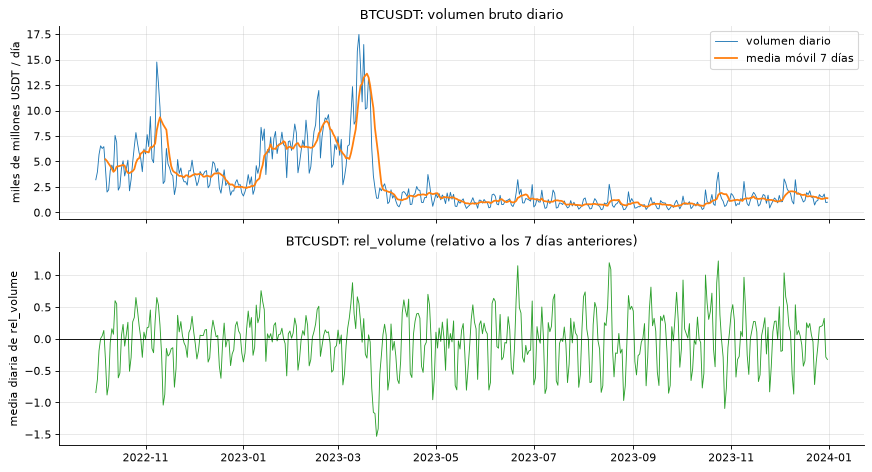

,volumen diario medio (miles de M USDT),rel_volume medio
2022Q4,4.45779,-0.04876
2023Q1,6.63563,-0.01102
2023Q2,1.33682,-0.02273
2023Q3,0.84546,-0.02886
2023Q4,1.34393,0.03210


In [13]:
# Volumen diario bruto de BTC de 2022T4 a 2023T4 y rel_volume medio diario de los paneles cacheados.
quarters_btc = ["2022-10-01", "2023-01-01", "2023-04-01", "2023-07-01", "2023-10-01"]
btc_start, btc_end = period_info("2022-10-01")[1], period_info("2023-10-01")[2]
btc_volume = align_klines(["BTCUSDT"], "1m", btc_start, btc_end, fields=("quote_asset_volume",))[
    "quote_asset_volume"
]["BTCUSDT"]
daily_volume = btc_volume.resample("1D").sum() / 1e9  # miles de millones de USDT por día

btc_rel = pd.concat(
    [
        read_panel(q, features=["rel_volume"], symbols=["BTCUSDT"]).features["rel_volume"][
            "BTCUSDT"
        ]
        for q in quarters_btc
    ]
)
daily_rel = btc_rel.resample("1D").mean()

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(daily_volume.index, daily_volume, lw=0.8, label="volumen diario")
axes[0].plot(daily_volume.index, daily_volume.rolling(7).mean(), lw=1.6, label="media móvil 7 días")
axes[0].set_ylabel("miles de millones USDT / día")
axes[0].set_title("BTCUSDT: volumen bruto diario")
axes[0].legend()
axes[1].plot(daily_rel.index, daily_rel, lw=0.8, color="tab:green")
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_ylabel("media diaria de rel_volume")
axes[1].set_title("BTCUSDT: rel_volume (relativo a los 7 días anteriores)")
plt.tight_layout()
plt.show()

# Medias por trimestre (to_period descarta la zona horaria: todo está en UTC).
by_quarter = pd.DataFrame(
    {
        "volumen diario medio (miles de M USDT)": daily_volume.groupby(
            daily_volume.index.tz_localize(None).to_period("Q")
        ).mean(),
        "rel_volume medio": daily_rel.groupby(
            daily_rel.index.tz_localize(None).to_period("Q")
        ).mean(),
    }
)
display(by_quarter)

**Interpretación.** El volumen diario de BTC pasa de una media de **6,6 miles de millones de USDT al día en 2023T1** (con un pico de unos 17,5 mil millones a mediados de marzo, visible en la figura) a **1,3 en 2023T2 y 0,85 en 2023T3**: un cambio de nivel de entre 5 y 8 veces. Una normalización con el histórico completo leería ese año como inactividad. `rel_volume` no lo refleja como nivel: su media trimestral queda en −0,049, −0,011, −0,023, −0,029 y +0,032, siempre cerca de 0. La caída de finales de marzo sí deja una huella corta (la media diaria baja hasta cerca de −1,5) y en pocos días vuelve a oscilar alrededor de 0, cuando la base de 7 días se ha puesto al día. La oscilación de ±1 que se ve el resto del tiempo parece un ciclo semanal (no se ha verificado).

### 2.8 El panel por trimestre y `to_array` (MIAX-041, D-24)

**Problema.** El grafo y la GNN necesitan **un solo objeto** con todas las features alineadas. Y un panel de los ocho años seguidos no cabe en memoria ni respeta el universo, que cambia cada trimestre.

**Qué se hace.** `build_panel` construye un `Panel` por trimestre y símbolos explícitos: `features` (un `DataFrame tiempo × moneda` por feature, mismo índice y columnas, `float64`), `valid` (`bool`), `interval` y `symbols`. `to_array()` los apila en un array `(T, N, F)` con los `NaN` conservados. Cada feature es exactamente la salida de su función `*_from_cache`. El panel lleva `valid`, no la causa del hueco (D-17). **`LUNAUSDT` no se parte:** su parada de 26 240 minutos ya deja `NaN` los retornos que la cruzan y la base de 7 días se queda sin datos hasta recuperar cobertura.

**Ejemplo.** El panel de 2025T1 (leído de la caché) y el de 2022T2 para comprobar LUNA.

In [14]:
# Panel de 2025T1 completo desde la caché (cached_panel lo lee; solo lo reconstruiría si faltase).
symbols_25, s25, e25 = period_info("2025-01-01")
panel = cached_panel(symbols_25, "1m", s25, e25)

print("features:", list(panel.features), "| intervalo:", panel.interval)
print("forma (T, N, F):", panel.shape)
array = panel.to_array()
print(
    f"to_array(): {array.shape}, dtype {array.dtype}, {array.nbytes / 1e6:.0f} MB, NaN conservados: {int(np.isnan(array).sum())}"
)
print("Orden de las features en el array:", list(panel.features))

# Primeras filas de un puñado de monedas: la fila 00:00 usa velas del 31-dic (pasado), no del 1-ene.
display(panel.features["return"].iloc[:3, :4])

# % de NaN por feature (en todo el panel).
nan_pct = pd.Series(
    {name: 100 * frame.isna().to_numpy().mean() for name, frame in panel.features.items()}
)
display(nan_pct.to_frame("% de NaN"))

features: ['return', 'realized_vol', 'rel_volume', 'rel_trades'] | intervalo: 1m
forma (T, N, F): (129600, 40, 4)
to_array(): (129600, 40, 4), dtype float64, 166 MB, NaN conservados: 88023
Orden de las features en el array: ['return', 'realized_vol', 'rel_volume', 'rel_trades']


,BTCUSDT,ETHUSDT,SOLUSDT,DOGEUSDT
2025-01-01 00:00:00+00:00,-0.00026,-0.00019,-0.00074,-0.00032
2025-01-01 00:01:00+00:00,0.00037,0.00006,0.00211,0.00019
2025-01-01 00:02:00+00:00,0.00044,0.00026,0.00000,0.00101


,% de NaN
return,0.55708
realized_vol,0.55471
rel_volume,0.29309
rel_trades,0.29309


**Interpretación.** El panel de 2025T1 tiene 129 600 filas (90 días × 1 440 minutos), 40 monedas y 4 features: forma `(129600, 40, 4)`, un array `float64` de 166 MB con **88 023 `NaN` conservados** (el 0,4 % de 20,7 millones de celdas). Por feature, `return` tiene un 0,56 % de `NaN`, `realized_vol` un 0,55 % y `rel_volume` y `rel_trades` un 0,29 %. Que `return` tenga casi el doble que `rel_*` es la consecuencia de D-18: el retorno necesita dos velas válidas seguidas y la actividad relativa solo una. La primera fila (00:00 del 1 de enero) ya tiene retornos con valor porque usa velas del 31 de diciembre, es decir, del pasado.

In [15]:
# LUNAUSDT en 2022T2: el panel no se parte; solo queda NaN lo que no se puede calcular.
luna = read_panel("2022-04-01", symbols=["LUNAUSDT"])
rows_luna = len(luna.valid)
luna_summary = pd.Series(
    {
        "filas del trimestre": rows_luna,
        "filas con valid=False": int((~luna.valid["LUNAUSDT"]).sum()),
        "retornos no NaN": int(luna.features["return"]["LUNAUSDT"].notna().sum()),
        "rel_volume no NaN": int(luna.features["rel_volume"]["LUNAUSDT"].notna().sum()),
        "realized_vol no NaN con valid=False": int(
            (luna.features["realized_vol"]["LUNAUSDT"].notna() & ~luna.valid["LUNAUSDT"]).sum()
        ),
    }
)
display(luna_summary.to_frame("LUNAUSDT 2022T2"))
# Qué filas explican las cifras (el índice del panel es el de cierre): tramos con valid=False y casos puntuales.
is_valid = luna.valid["LUNAUSDT"]
invalid = ~is_valid
block = (invalid != invalid.shift()).cumsum()[invalid]  # un número por tramo seguido de valid=False
vol_extra = luna.features["realized_vol"]["LUNAUSDT"].notna() & invalid
times = invalid[invalid].index.to_series()
runs_luna = pd.DataFrame(
    {
        "inicio": times.groupby(block).first(),
        "fin": times.groupby(block).last(),
        "minutos": times.groupby(block).size(),
        "realized_vol con valor": vol_extra[invalid].groupby(block).sum(),
    }
)
display(runs_luna)
vol_times = vol_extra.index[vol_extra.to_numpy()]
print("realized_vol con valor y valid=False:", ", ".join(f"{t:%d-%b %H:%M}" for t in vol_times))
no_return = is_valid & luna.features["return"]["LUNAUSDT"].isna()
no_return_times = no_return.index[no_return.to_numpy()]
print("Minutos válidos sin retorno:", ", ".join(f"{t:%d-%b %H:%M}" for t in no_return_times))

,LUNAUSDT 2022T2
filas del trimestre,131040
filas con valid=False,26241
retornos no NaN,104797
rel_volume no NaN,99759
realized_vol no NaN con valid=False,13


,inicio,fin,minutos,realized_vol con valor
LUNAUSDT,,,,
2,2022-05-13 00:41:00+00:00,2022-05-31 06:00:00+00:00,26240,12
4,2022-06-25 03:40:00+00:00,2022-06-25 03:40:00+00:00,1,1


realized_vol con valor y valid=False: 13-May 00:41, 13-May 00:42, 13-May 00:43, 13-May 00:44, 13-May 00:45, 13-May 00:46, 13-May 00:47, 13-May 00:48, 13-May 00:49, 13-May 00:50, 13-May 00:51, 13-May 00:52, 25-Jun 03:40
Minutos válidos sin retorno: 31-May 06:01, 25-Jun 03:41


**Interpretación.** El panel de LUNAUSDT en 2022T2 sigue teniendo las **131 040 filas** del trimestre: no se parte. `valid=False` en 26 241 filas: los 26 240 minutos de la parada (del 13-may 00:41 al 31-may 06:00, en el índice de cierre) más 1 minuto sin operaciones (25-jun 03:40), como muestra la tabla de tramos. Hay 104 797 retornos, dos menos que minutos válidos (104 799): faltan los de los dos primeros minutos válidos tras un tramo inválido, cuyo retorno saltaría el hueco; son uno tras la parada (31-may 06:01) y otro tras el minuto sin operaciones (25-jun 03:41). `rel_volume` tiene 99 759 valores, **5 040 menos** que los minutos válidos: tras una parada de 26 240 minutos, la base de 7 días (10 080 velas) queda vacía y no recupera el 50 % de cobertura hasta que hay 5 040 velas válidas. `realized_vol` conserva 13 valores con `valid=False`: 12 son los primeros minutos de la parada (13-may 00:41 a 00:52), mientras la ventana de 60 retornos aún tiene el 80 % de cobertura, y 1 es el minuto sin operaciones del 25-jun 03:40, que cae dentro de una ventana con cobertura suficiente (el contrato permite que `realized_vol` tenga valor con `valid=False`).

### 2.9 Barras de 5, 15 y 60 minutos desde 1 minuto (MIAX-042, D-23)

**Problema.** Rebalancear y predecir cada minuto condena el test económico por construcción (D-04), así que se evalúan varios horizontes. Pero descargar velas de 5/15/60 minutos y mezclarlas con las de 1 minuto da incoherencias entre horizontes.

**Qué se hace.** Las barras **salen siempre de las velas de 1 minuto** y su validez se **recalcula**: una barra es válida si su **último minuto es válido** y la fracción de minutos válidos es **≥ 80 %** (`min_valid_share = 0.8`; con 1.0 sería la regla estricta). Agregación por campo: `open` el primer minuto válido, `high`/`low` el máximo/mínimo de los válidos (los `NO_TRADES` se excluyen porque su OHLC es el cierre repetido), `close` el último, `volume`, `num_trades` y similares la suma de lo observado, **sin reescalar**. Lo no válido es `NaN`. Las barras van alineadas al reloj y los retornos se indexan por `open_time + H` (D-19). No se puentea un hueco.

**Ejemplo 1.** Los 30 minutos de `CHZUSDT` (20-jul-2026 19:00 a 19:30) como dos barras de 15 minutos, junto a los minutos de los que sale la primera. Un minuto sin operaciones repite el precio anterior: no puede ser el `open` de la barra ni entrar en su máximo o mínimo.

In [16]:
# Dos barras de 15 minutos de CHZUSDT y los minutos de los que sale la primera.
b_start, b_end = ms("2026-07-20 19:00"), ms("2026-07-20 19:30")
fields_bar = ("open", "high", "low", "close", "num_trades")
bars, bar_valid = resample_from_cache(["CHZUSDT"], "1m", "15m", b_start, b_end, fields=fields_bar)

# Los 30 minutos tal como vienen de Binance y su validez (para entender por qué cada barra vale o no).
minutes = align_klines(["CHZUSDT"], "1m", b_start, b_end, fields=fields_bar)
minutes_valid = validity_mask(classify_klines(["CHZUSDT"], "1m", b_start, b_end))["CHZUSDT"]
per_bar = minutes_valid.groupby(minutes_valid.index.floor("15min"))

bar_table = pd.concat({**bars, "válida": bar_valid}, axis=1).droplevel(1, axis=1)
bar_table["minutos válidos (de 15)"] = per_bar.sum()
bar_table["último minuto válido"] = per_bar.last()
bar_table.index.name = "barra abierta a las"
display(bar_table)

# Los 15 minutos de la primera barra, tal como vienen.
first_bar = pd.concat({k: v["CHZUSDT"] for k, v in minutes.items()}, axis=1).iloc[:15]
first_bar["válido"] = minutes_valid.iloc[:15]
first_bar.index.name = "minuto abierto a las"
display(first_bar)

,open,high,low,close,num_trades,válida,minutos válidos (de 15),último minuto válido
barra abierta a las,,,,,,,,
2026-07-20 19:00:00+00:00,0.01532,0.01532,0.01527,0.01527,131.0,True,14,True
2026-07-20 19:15:00+00:00,NaN,NaN,NaN,NaN,NaN,False,11,True


,open,high,low,close,num_trades,válido
minuto abierto a las,,,,,,
2026-07-20 19:00:00+00:00,0.01530,0.01530,0.01530,0.01530,0.0,False
2026-07-20 19:01:00+00:00,0.01532,0.01532,0.01532,0.01532,15.0,True
2026-07-20 19:02:00+00:00,0.01531,0.01531,0.01530,0.01530,20.0,True
2026-07-20 19:03:00+00:00,0.01529,0.01530,0.01529,0.01530,2.0,True
2026-07-20 19:04:00+00:00,0.01529,0.01530,0.01529,0.01530,4.0,True
2026-07-20 19:05:00+00:00,0.01530,0.01530,0.01530,0.01530,2.0,True
2026-07-20 19:06:00+00:00,0.01530,0.01530,0.01530,0.01530,1.0,True
2026-07-20 19:07:00+00:00,0.01530,0.01530,0.01530,0.01530,7.0,True
2026-07-20 19:08:00+00:00,0.01530,0.01531,0.01529,0.01531,28.0,True


**Interpretación.** La barra de 19:00 a 19:15 es **válida**: 14 de sus 15 minutos lo son (93 %) y el último también. El minuto 19:00 no tuvo operaciones y repite el cierre anterior (0,01530), por eso el `open` de la barra es el del primer minuto válido, **0,01532 (19:01)**, y no 0,01530. `high` (0,01532) y `low` (0,01527) salen solo de minutos válidos, `close` es el del último minuto (0,01527) y `num_trades` suma lo observado (131, sin reescalar). La barra de 19:15 sale **`NaN` en todos los campos**: solo 11 de sus 15 minutos son válidos (73 %, por debajo del 80 %), aunque el último sí lo es.

**Ejemplo 2: por qué el 80 %.** Con la regla estricta (todos los minutos válidos) una moneda poco líquida pierde muchísimas barras; con el 80 % se pierden pocas. Se compara el % de barras válidas de `1000SATSUSDT` en 2025T1 con tres reglas: estricta (100 %), el 80 % elegido, y exigir solo el último minuto (la más permisiva).

In [17]:
# % de barras válidas de 1000SATSUSDT en 2025T1 con tres reglas de cobertura.
sats = read_panel("2025-01-01", symbols=["1000SATSUSDT"])
# Cada regla da la cobertura mínima según cuántos minutos tiene la barra (5, 15 o 60).
rules = {
    "estricta (100 %)": lambda minutes: 1.0,
    "elegida (80 %)": lambda minutes: 0.8,
    "solo último minuto": lambda minutes: 1 / minutes,  # basta 1 minuto válido (el último)
}
horizon_minutes = {"5m": 5, "15m": 15, "60m": 60}
rows = {}
for label, share_for in rules.items():
    row = {}
    for horizon, minutes in horizon_minutes.items():
        pct = bar_validity_pct(sats, (horizon,), min_valid_share=share_for(minutes))
        row[horizon] = pct.loc["1000SATSUSDT", horizon]
    rows[label] = row
display(pd.DataFrame(rows).T.rename_axis("regla"))

# Lo mismo con el año 2025 entero, que es lo que mide D-23. 1000SATS solo está en el universo de
# 2025T1, así que se parte de sus velas (validez y barras con las mismas funciones del panel).
valid_year = validity_mask(
    classify_klines(["1000SATSUSDT"], "1m", ms("2025-01-01"), ms("2026-01-01"))
)
rows_year = {
    label: {
        horizon: 100
        * resample_validity(valid_year, "1m", horizon, min_valid_share=share_for(minutes))
        .mean()
        .iloc[0]
        for horizon, minutes in horizon_minutes.items()
    }
    for label, share_for in rules.items()
}
print("Año 2025 entero:")
display(pd.DataFrame(rows_year).T.rename_axis("regla"))

,5m,15m,60m
regla,,,
estricta (100 %),89.28971,79.87036,66.23437
elegida (80 %),95.12713,94.05024,94.39555
solo último minuto,96.73984,96.51580,97.17462


Año 2025 entero:


,5m,15m,60m
regla,,,
estricta (100 %),84.26465,71.74372,52.92237
elegida (80 %),91.87785,89.81735,88.96119
solo último minuto,94.51865,93.57591,93.18493


**Interpretación.** En `1000SATSUSDT` (2025T1) la regla estricta deja válidas solo el **89,3 %** de las barras de 5 minutos, el **79,9 %** de las de 15 y el **66,2 %** de las de 60: a una hora se pierde una barra de cada tres. Con el 80 % elegido quedan 95,1 %, 94,1 % y 94,4 %. Exigir solo el último minuto da 96,7 %, 96,5 % y 97,2 % (entre 1,6 y 2,8 puntos más que el 80 %), pero acepta barras con un solo minuto observado. El 80 % recupera casi todo lo que la estricta pierde sin aceptar barras casi vacías. Estas cifras difieren de las de D-23 (hasta 13 puntos: a 60 minutos, 66,2 % frente a 52,9 % con la regla estricta) porque D-23 mide 1000SATS en el año 2025 entero y aquí solo 2025T1. Con el año entero (segunda tabla) se reproducen las de D-23: 84,3 %, 71,7 % y 52,9 % con la estricta; 91,9 %, 89,8 % y 89,0 % con el 80 %; y 93,2 % a 60 minutos exigiendo solo el último minuto.

**Ejemplo 3: retornos a 15 minutos.** Se calculan con el mismo código que a 1 minuto sobre las barras (`horizon_returns_from_cache`) y se indexan por `open_time + H` (D-19): el retorno de la barra de 10:00 a 10:15 va en la fila **10:15**.

In [18]:
# Retornos de 15 minutos de BTCUSDT el 2-ene-2025 y cierres de las barras de las que salen.
h_start, h_end = ms("2025-01-02 10:00"), ms("2025-01-02 11:00")
h_returns = horizon_returns_from_cache(["BTCUSDT"], "15m", h_start, h_end)[
    "BTCUSDT"
]  # filas 10:00 ... 10:45
h_bars, _ = resample_from_cache(
    ["BTCUSDT"], "1m", "15m", h_start - 900_000, h_end, fields=("close",)
)
close_15 = h_bars["close"]["BTCUSDT"]

demo15 = pd.DataFrame({"close de la barra": close_15})
demo15.index.name = "barra abierta a las"
demo15["se conoce a las"] = shift_to_close(demo15.index, "15m")  # open_time + 15 min
demo15["ln(P_t / P_t-1) a mano"] = np.log(close_15).diff()
demo15["retorno del pipeline"] = h_returns.reindex(demo15["se conoce a las"]).to_numpy()
display(demo15)

,close de la barra,se conoce a las,ln(P_t / P_t-1) a mano,retorno del pipeline
barra abierta a las,,,,
2025-01-02 09:45:00+00:00,96755.51,2025-01-02 10:00:00+00:00,NaN,0.00420
2025-01-02 10:00:00+00:00,96606.14,2025-01-02 10:15:00+00:00,-0.00154,-0.00154
2025-01-02 10:15:00+00:00,96697.95,2025-01-02 10:30:00+00:00,0.00095,0.00095
2025-01-02 10:30:00+00:00,96610.39,2025-01-02 10:45:00+00:00,-0.00091,-0.00091
2025-01-02 10:45:00+00:00,96708.00,2025-01-02 11:00:00+00:00,0.00101,NaN


**Interpretación.** La barra de 10:00 a 10:15 (cierre 96 606,14) tiene su retorno, −0,0015, en la fila **10:15**; coincide con el cálculo a mano en las tres filas comparables (10:15, 10:30 y 10:45). La fila de 10:00 (retorno de la barra de 09:45) no tiene cálculo a mano porque su barra anterior queda fuera de la tabla, aunque el pipeline sí la calcula; y la de 11:00 queda fuera del rango pedido (el fin es exclusivo), así que el pipeline no la da. La convención es la misma que a 1 minuto: una fila solo contiene lo que se sabía en ese instante.

### 2.10 Caché Parquet del panel (MIAX-043, D-26)

**Problema.** Construir un trimestre de 40 monedas tarda del orden de 10 segundos; el periodo es la unidad con la que se construye y se consume.

**Qué se hace.** `data/processed/panel/{intervalo}/{inicio}_{fin}/` guarda **un directorio por periodo** y, dentro, **un Parquet por feature** más `valid.parquet` y un `meta.json`. Parquet permite leer solo `return` (lo que usará el grafo) o solo unos símbolos. `meta.json` se escribe **el último** y de forma atómica (un directorio sin él no es caché válida) y lleva la **huella** de la caché de velas, por lo que cambiar las velas, los símbolos, el rango, los parámetros o `FEATURES_VERSION` invalida y reconstruye el panel. Ida y vuelta idéntica bit a bit.

**Ejemplo.** Contenido de la caché de 2025T1, comparación con una construcción desde cero y lectura parcial.

In [19]:
# Contenido del directorio del panel 2025T1 (rutas relativas al repo).
directory = panel_path("1m", s25, e25)
files = pd.DataFrame(
    [
        {"fichero": f.name, "tamaño (MB)": f.stat().st_size / 1e6}
        for f in sorted(directory.iterdir())
    ]
)
print("Directorio:", directory.relative_to(REPO).as_posix())
display(files)

# meta.json sin la lista de símbolos ni la huella (que son largas).
meta = json.loads((directory / "meta.json").read_text(encoding="utf-8"))
brief = {k: v for k, v in meta.items() if k not in ("symbols", "fingerprint")}
brief["symbols"] = f"{len(meta['symbols'])} símbolos"
brief["fingerprint"] = (
    f"{len(meta['fingerprint'])} símbolos con (nombre, tamaño) de cada fichero mensual"
)
print(json.dumps(brief, indent=2, ensure_ascii=False))

# Tamaño total de la caché de paneles.
total = sum(f.stat().st_size for f in (REPO / "data/processed/panel/1m").rglob("*") if f.is_file())
print(f"\nCaché de los {len(overview.periods)} paneles: {total / 1e9:.2f} GB")

Directorio: data/processed/panel/1m/2025-01-01_2025-04-01


,fichero,tamaño (MB)
0,meta.json,0.13198
1,realized_vol.parquet,51.31706
2,rel_trades.parquet,53.05068
3,rel_volume.parquet,53.05704
4,return.parquet,28.17487
5,valid.parquet,1.12053


{
  "format_version": 1,
  "features_version": 1,
  "interval": "1m",
  "start_ms": 1735689600000,
  "end_ms": 1743465600000,
  "features": [
    "return",
    "realized_vol",
    "rel_volume",
    "rel_trades"
  ],
  "params": {
    "vol_window": 60,
    "vol_min_valid_share": 0.8,
    "activity_window": 10080,
    "activity_min_valid_share": 0.5
  },
  "created_at": "2026-10-30T16:15:38.438258+00:00",
  "symbols": "40 símbolos",
  "fingerprint": "40 símbolos con (nombre, tamaño) de cada fichero mensual"
}

Caché de los 35 paneles: 4.66 GB


**Interpretación.** El panel de 2025T1 son cinco Parquet y un `meta.json`: `return` pesa 28 MB, `realized_vol` 51 MB, `rel_volume` y `rel_trades` 53 MB cada uno y `valid` 1,1 MB. El `meta.json` (132 KB, casi todo la huella de las velas de las 40 monedas) guarda las versiones del formato y de las features, el rango en milisegundos y los parámetros con que se construyó (ventana de volatilidad 60 con mínimo 80 %, ventana de actividad 10 080 con mínimo 50 %). Es lo que permite detectar una caché obsoleta. Los 35 paneles ocupan 4,66 GB en `data/processed/panel/1m` (carpeta ignorada por git, como todos los datos).

In [20]:
# Construir desde cero frente a leer de la caché, y comprobar que el resultado es idéntico.
t0 = time.time()
rebuilt = build_panel(symbols_25, "1m", s25, e25)
t_build = time.time() - t0

t0 = time.time()
loaded = read_panel("2025-01-01")
t_load = time.time() - t0

same = all(
    rebuilt.features[name].equals(loaded.features[name]) for name in rebuilt.features
) and rebuilt.valid.equals(loaded.valid)
print(f"Construir: {t_build:.1f} s | leer de la caché: {t_load:.1f} s | idénticos: {same}")

# Lectura parcial: solo los retornos de dos monedas.
t0 = time.time()
partial = read_panel("2025-01-01", features=["return"], symbols=["BTCUSDT", "ETHUSDT"])
print(f"Lectura parcial (return, 2 monedas): {partial.shape} en {time.time() - t0:.2f} s")

Construir: 9.2 s | leer de la caché: 0.2 s | idénticos: True
Lectura parcial (return, 2 monedas): (129600, 2, 1) en 0.02 s


**Interpretación.** Construir el panel de 2025T1 desde las velas tarda unos segundos y leerlo de la caché una fracción de segundo; el resultado es **idéntico** (`equals` en las cuatro features y en `valid`). La lectura parcial de solo `return` para dos monedas es todavía más rápida: es lo que usará el grafo, que no necesita las otras features.

### 2.11 El contrato A → B y `validate_panel` (MIAX-044, D-29)

**Problema.** Para que la Épica 3 consuma el panel sin preguntar, las garantías tienen que ser explícitas y **comprobarse por código**: si no, un cero en un hueco, un retorno que salta un hueco o un `inf` se cuelan en el grafo.

**Qué se hace.** `docs/datos/contrato-a-b.md` describe el esquema y `validate_panel` lo hace cumplir. Se ejecuta **siempre** al final de `build_panel` y de `load_panel`, así que un panel que lo incumple no sale de A. Comprueba: features conocidas, índice `datetime64[ms, UTC]` con paso regular, ningún `±inf`, `NaN` en `return`, `rel_volume` y `rel_trades` donde `valid=False`, ningún `return` que puentee un hueco, y `realized_vol ≥ 0`. Reúne todas las violaciones en un único `ValueError`.

**Esquema de las features** (definido en código en `FEATURE_SPECS`):

In [21]:
# Esquema del contrato tal como está definido en el código.
display(pd.DataFrame([asdict(spec) for spec in FEATURE_SPECS.values()]).set_index("name"))

,unit,description,nan_if_invalid,non_negative
name,,,,
return,"log-retorno, unidades naturales (no %)",ln P_t - ln P_{t-1} del cierre; solo existe si...,True,False
realized_vol,"desviacion tipica del retorno de 1 paso, sin a...",sqrt((W/n) * sum(r^2)) de los W retornos anter...,False,True
rel_volume,"diferencia de logaritmos, sin unidad",ln(volumen en quote) menos la media de ln V de...,True,False
rel_trades,"diferencia de logaritmos, sin unidad",ln(numero de operaciones) menos la media de ln...,True,False


**Interpretación.** El contrato fija, por feature, tres cosas. `return`, `rel_volume` y `rel_trades` **deben ser `NaN` donde la vela no es válida** (`nan_if_invalid = True`), por eso `fillna(0)` o un retorno en un hueco lo rompen (el ejemplo siguiente). `realized_vol` es la excepción: **puede tener valor con `valid=False`** (es una ventana de 60 retornos), pero **no puede ser negativa** (`non_negative = True`); es la única con esa restricción, porque `return` y las dos actividades relativas son diferencias de logaritmos y pueden ser negativas. Las unidades están en la columna `unit`: log-retornos sin porcentaje, desviación típica sin anualizar y diferencias de logaritmos sin unidad.

**Ejemplo: un panel manipulado falla.** Se parte de un panel real (2026T3, con `WLFIUSDT` llena de huecos) y se hacen tres cosas que el contrato prohíbe: rellenar huecos con 0, meter un `inf`, y poner un retorno en un slot inválido.

In [22]:
# Panel real 2026T3 (ya validado al cargarlo) y tres manipulaciones. Se copia antes de tocar.
real = read_panel("2026-07-01")
validate_panel(real)  # sin excepción: el panel real cumple el contrato
print("Panel real 2026T3: contrato cumplido")


def tampered(name, change):
    # Copia las features, aplica el cambio y devuelve un Panel nuevo (el real no se toca).
    features = {key: frame.copy() for key, frame in real.features.items()}
    change(features)
    return name, Panel(
        features=features, valid=real.valid.copy(), interval=real.interval, symbols=real.symbols
    )


def fill_zeros(features):
    features["return"] = features["return"].fillna(0.0)  # el error clásico: D-02


def put_inf(features):
    features["rel_volume"].iloc[100, 0] = np.inf


def return_in_invalid_slot(features):
    # Un retorno donde la vela no es válida (WLFIUSDT tiene muchos minutos sin operaciones).
    column = list(real.symbols).index("WLFIUSDT")
    row = int(np.flatnonzero(~real.valid["WLFIUSDT"].to_numpy())[10])
    features["return"].iloc[row, column] = 0.001


for name, change in [
    ("fillna(0) en return", fill_zeros),
    ("inf en rel_volume", put_inf),
    ("retorno en slot inválido", return_in_invalid_slot),
]:
    label, bad_panel = tampered(name, change)
    try:
        validate_panel(bad_panel)
        print(f"[{label}] NO falló (esto sería un fallo del contrato)")
    except ValueError as error:
        lines = str(error).splitlines()
        print(f"[{label}] ValueError:")
        for line in lines[:4]:
            print("   ", line[:200])

Panel real 2026T3: contrato cumplido
[fillna(0) en return] ValueError:
    el panel no cumple el contrato A -> B:
    - return: valor no NaN en velas no validas: 285758 celdas; primer instante 2026-07-01 00:00:00+00:00 (TONUSDT)
    - return: puentea un hueco (retorno con la vela anterior no valida): 285757 celdas; primer instante 2026-07-01 00:01:00+00:00 (TONUSDT)


[inf en rel_volume] ValueError:
    el panel no cumple el contrato A -> B:
    - rel_volume: valores infinitos: 1 celdas; primer instante 2026-07-01 01:40:00+00:00 (BTCUSDT)
[retorno en slot inválido] ValueError:
    el panel no cumple el contrato A -> B:
    - return: valor no NaN en velas no validas: 1 celdas; primer instante 2026-07-01 03:32:00+00:00 (WLFIUSDT)


**Interpretación.** El panel real cumple el contrato. Las tres manipulaciones fallan con un único `ValueError` que dice qué feature, cuántas celdas, el primer instante y la moneda: `fillna(0)` en `return` produce 285 758 celdas con valor en velas no válidas (y 285 757 retornos que puentean un hueco); un `inf` en `rel_volume` se detecta en 1 celda (BTCUSDT, 1-jul 01:40); y un retorno de 0,001 en una vela no válida de WLFIUSDT se detecta en 1 celda (1-jul 03:32). El primer instante del `fillna(0)` cita a `TONUSDT` porque su columna entera `NaN` también se rellena. Esta red es la que impide que un 0 o un `inf` lleguen al grafo.

### 2.12 La red de tests de huecos (MIAX-045)

**Problema.** El tratamiento de huecos es el riesgo número uno de fuga y de falsos positivos: un fallo sutil (rellenar con 0, puentear un hueco, dar por válido un minuto sin operaciones) no hace ruido y estropea todo lo posterior.

**Qué se hace.** `tests/integration/test_preprocessing_gaps.py` monta un **mundo sintético** de 360 velas de 1 minuto que **cruza un cambio de mes** (dos ficheros de caché por símbolo) con 4 símbolos y casos pensados: una vela suelta que falta, cinco seguidas a caballo de la medianoche, un tramo sin operaciones, un retorno 0 auténtico, un listado tardío, un deslistado y una caída común. Un **oráculo independiente** (bucles de Python, sin usar `miax.features`) da la validez y el retorno esperados, y `build_panel` y `returns_from_cache` deben coincidir con él exactamente. Se comprobó también por **mutaciones**: estropear a propósito el tratamiento de huecos hace fallar el test que corresponde.

**Cuántos tests son.** El fichero tiene 10 funciones `def test_`; las dos últimas están parametrizadas por mutación y, al expandir `parametrize`, pytest cuenta 17 casos. Los «unos 17 casos y ~3 s, sin red» vienen de la entrada de MIAX-045 en `docs/project/ESTADO.md`, no del ticket. Aquí no se ejecuta pytest: la red corre con `pytest` desde la raíz del repo. Comprueba que `build_panel` y `returns_from_cache` coinciden con el oráculo, que todas las columnas comparten rejilla al cruzar el cambio de mes, que un hueco a caballo de la medianoche queda `NaN` y no se puentea, que no se inyecta ningún 0 pero el 0 auténtico sobrevive, y que `classify_klines` etiqueta cada escenario (incluido `NOT_LISTED` si el listado es conocido). Los tests de mutaciones estropean a propósito el tratamiento de huecos y exigen que la red lo detecte.

### 2.13 Correlación cruda y monedas sin datos (MIAX-046 y 213, D-30)

**Problema.** Antes de quitar el factor común (Épica 3) hay que ver **cuánto se parecen entre sí** los retornos del universo. Es la «foto del antes»: si casi todo se mueve con BTC, cualquier lead-lag medido sin residualizar es un espejismo.

**Qué se hace.** Correlación de Pearson por pares sobre `return` válido y sin recortar (D-22), con `min_periods = 1000` observaciones comunes. Las monedas se ordenan **por categoría** (BTC primero) y no por agrupación jerárquica: la categoría es una etiqueta externa y no fabrica bloques; ordenar por la propia correlación los fabricaría incluso en un mercado de un solo factor. Se resume con la correlación media entre pares, el % de pares con correlación > 0,5, la correlación con BTC y la varianza que explica cada componente principal de la matriz.

**MIAX-213 (monedas sin datos).** Una moneda deslistada **dentro** del trimestre es legítima en el universo (D-14), como `TONUSDT` en 2026T3 (Binance dejó de cotizarla el 30-jun-2026): su columna sale entera `NaN`. Antes eso hacía fallar el informe (sus 31 pares eran el 6,2 % de los pares, por encima del límite del 5 %). Ahora la moneda **se aparta del resumen y de los componentes principales**, se nombra en la figura, sigue en el mapa (en **gris**, para que no parezca una correlación 0) y no se rellena nada con 0.

**Ejemplo.** 2026T3, con `TONUSDT` apartada. La función `summarize_correlation` es la que usan el informe y este notebook.

In [23]:
# Correlación cruda de 2026T3: la moneda sin datos se detecta, se aparta y se anota.
symbols_26, s26, e26 = period_info("2026-07-01")
rows_26 = universe[universe["period_start"] == pd.Timestamp("2026-07-01", tz="UTC")]
categories = dict(zip(rows_26["symbol"], rows_26["category"]))
order = order_by_category(symbols_26, categories)  # BTC primero y luego por categoría

returns_26 = read_panel("2026-07-01", features=["return"]).features["return"][order]
corr_26 = raw_correlation(returns_26, min_periods=1000)
print("Monedas sin datos (diagonal NaN):", symbols_without_data(corr_26))

summary_26, eigenvalues_26, without_26 = summarize_correlation(corr_26, label="2026T3")
cols = [
    "n_symbols",
    "n_pairs",
    "n_missing_pairs",
    "pair_mean",
    "pair_median",
    "pairs_above_high_pct",
    "factor_median",
    "factor_min_symbol",
    "factor_min",
    "factor_max_symbol",
    "factor_max",
    "first_eigenvalue_share",
    "second_eigenvalue_share",
]
display(pd.Series({c: summary_26[c] for c in cols}).to_frame("2026T3"))

2026-11-02T19:26:45Z | WARNING | miax.viz.raw_correlation | Periodo 2026T3: 1 simbolos sin datos, fuera del resumen y de los componentes: TONUSDT


Monedas sin datos (diagonal NaN): ['TONUSDT']


,2026T3
n_symbols,31
n_pairs,465
n_missing_pairs,0
pair_mean,0.40925
pair_median,0.43658
pairs_above_high_pct,31.39785
factor_median,0.51086
factor_min_symbol,TRXUSDT
factor_min,0.16076
factor_max_symbol,ETHUSDT


**Interpretación.** `TONUSDT` se detecta como moneda sin datos (diagonal `NaN`) y se aparta: quedan **31 monedas, 465 pares y ningún par ausente** (`n_missing_pairs = 0`), así que el límite del 5 % no salta. La correlación media entre pares es **0,409** (mediana 0,437) y solo el **31,4 %** de los pares supera 0,5. El 1.er componente explica el **45,5 %** de la varianza y el 2.º el 3,6 % (unas 12 veces menos). La correlación con BTC tiene mediana 0,511 (mínima `TRXUSDT` 0,161, máxima `ETHUSDT` 0,835). Es un factor común menos fuerte que en 2025T1 (66,0 %), pero el primer componente sigue dominando.

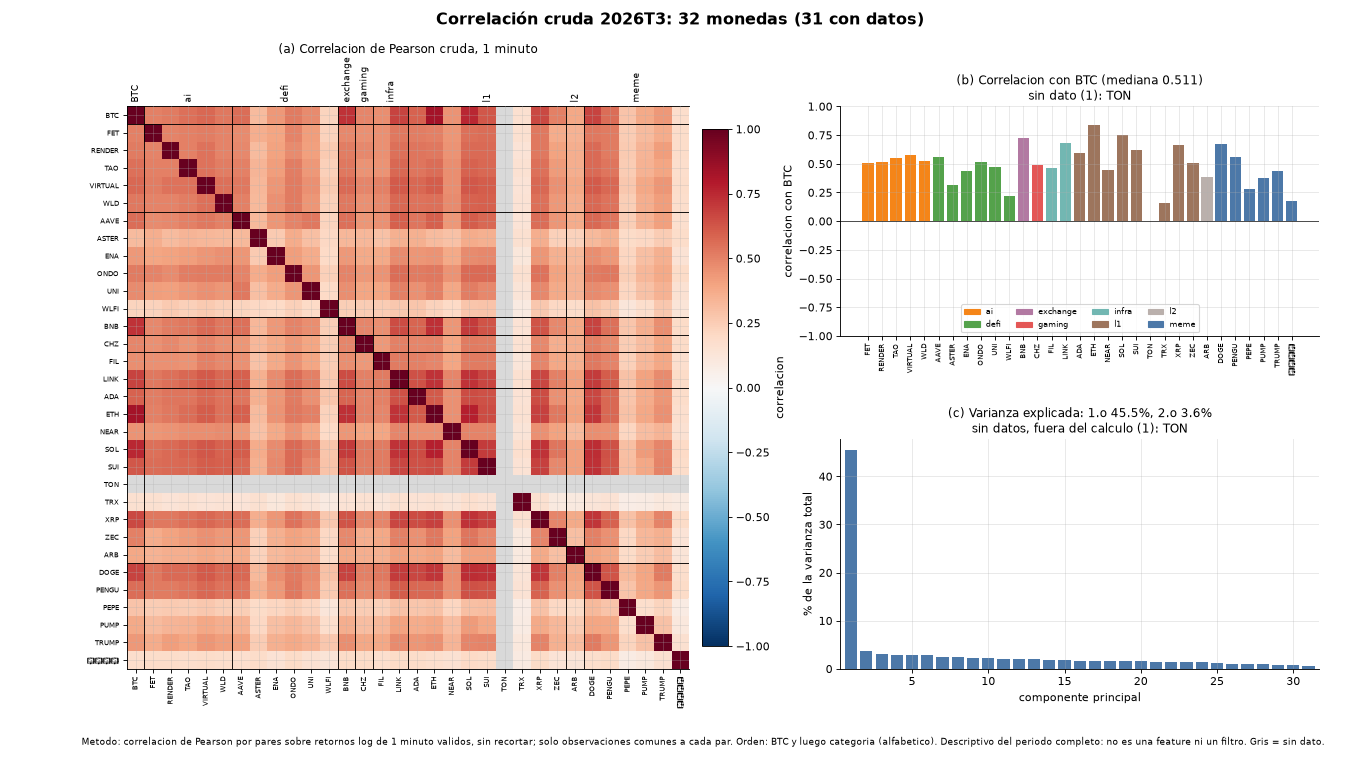

In [24]:
# La figura de tres paneles de MIAX-046 para 2026T3 (la etiqueta de 币安人生USDT sale en cuadros: la fuente no tiene esos glifos).
fig = plot_raw_correlation(
    corr_26,
    categories,
    summary_26,
    eigenvalues_26,
    title=f"Correlación cruda 2026T3: {len(order)} monedas ({len(order) - len(without_26)} con datos)",
    without_data=without_26,
)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # avisos de glifos ausentes (solo estética)
    show(fig)

**Interpretación.** En el mapa (a), `TONUSDT` es una fila y una columna **grises** (no blancas: el blanco de esta escala sería una correlación 0), no tiene barra en (b) y el título de (c) la nombra como moneda sin datos, fuera del cálculo. El resto del mapa va de tonos naranjas (correlaciones de 0,3 a 0,5) a rojos oscuros en `BTC`, `ETH`, `SOL`, `BNB`, `LINK`, `SUI`, `DOGE` y `XRP`; `WLFI` (la ilíquida de la sección 4.5), `PEPE` y `TRX` tienen filas y columnas claras, es decir, poco correlacionadas con casi todo. En (b), `ETH` es la más correlacionada con BTC (0,835) y `TRX` la menos (0,161). En (c), el primer componente (45,5 %) destaca sobre todos los demás, que quedan casi planos entre el 3,6 % y por debajo del 1 %. La etiqueta de la moneda china sale en cuadros por falta de glifos en la fuente (limitación conocida de la figura; no afecta a las cifras).

## 3. El universo trimestral: qué monedas hay en cada panel

El universo se elige **antes** de cada trimestre con el volumen de una ventana anterior (D-14, D-25), nunca con el del propio periodo: así no se usa el futuro y entran pares que entonces eran líquidos aunque hoy estén deslistados (sesgo de supervivencia). Además un par solo entra si cotizaba al cierre de su ventana (D-28). El trimestral es el universo **principal**; el semestral y el anual son pruebas de robustez.

**Ojo con el principio de la serie:** hasta 2021T1 el universo tiene pocas monedas porque en 2018-2020 las altcoins cotizaban sobre todo contra BTC y ETH, no contra USDT (`docs/datos/sesgo-supervivencia.md`).

### 3.1 Cuántas monedas por trimestre y categoría

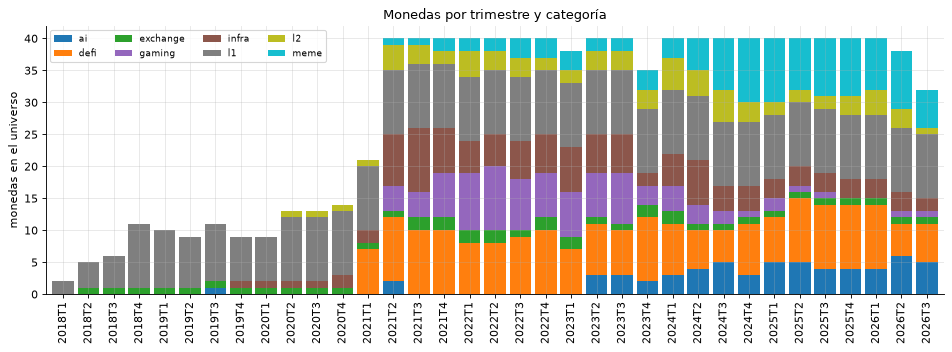

category,ai,defi,exchange,gaming,infra,l1,l2,meme,total
2018T1,0,0,0,0,0,2,0,0,2
2019T1,0,0,1,0,0,9,0,0,10
2020T1,0,0,1,0,1,7,0,0,9
2021T1,0,7,1,0,2,10,1,0,21
2021T2,2,10,1,4,8,10,4,1,40
2023T1,0,7,2,7,7,10,2,3,38
2025T1,5,7,1,2,3,10,2,10,40
2026T3,5,6,1,1,2,10,1,6,32


In [25]:
# Monedas por trimestre y categoría (barras apilables) y total.
by_category = universe.groupby(["period_start", "category"]).size().unstack(fill_value=0)
by_category.index = [qlabel(q) for q in by_category.index]

fig, ax = plt.subplots(figsize=(12, 4.5))
by_category.plot.bar(stacked=True, ax=ax, width=0.85, colormap="tab10")
ax.set_ylabel("monedas en el universo")
ax.set_xlabel("")
ax.set_title("Monedas por trimestre y categoría")
ax.legend(ncol=4, fontsize=8)
plt.tight_layout()
plt.show()

display(by_category.assign(total=by_category.sum(axis=1)).iloc[[0, 4, 8, 12, 13, 20, 28, 34]])

**Interpretación.** El universo crece con el tiempo: **2 monedas en 2018T1** (solo BTC y ETH pasan el filtro), 9-14 entre 2019 y 2020, **21 en 2021T1** y **40 desde 2021T2** (el tope por trimestre: `max_pairs: 40` en `configs/universe.yaml`). En los trimestres de 2019T1 y 2020T1 que se muestran casi todas son `l1` (más un `exchange` y, en 2020T1, un `infra`); la diversidad de categorías (`defi`, `gaming`, `infra`, `l2`, `ai`, `meme`) llega con 2021T2. Desde entonces son 40 casi siempre; bajan a 38 en 2023T1 y 2026T2, a 35 en 2023T4 y a 32 en 2026T3 (el universo toma las que superan el suelo de volumen de 5 M, hasta 40: con menos candidatas, baja). La composición cambia mucho: 2025T1 tiene 10 `meme` y 5 `ai`, frente a 1 `meme` y 2 `ai` en 2021T2, y `l1` se queda en 10 en todos los trimestres de 40 monedas: es el tope por categoría, `max_per_category: 10` en `configs/universe.yaml`.

### 3.2 Entradas y salidas entre trimestres

In [26]:
# Entradas y salidas: monedas que aparecen o desaparecen respecto al trimestre anterior.
members = universe.groupby("period_start")["symbol"].apply(set)
rows = []
previous = set()
for start, current in members.items():
    entering, leaving = sorted(current - previous), sorted(previous - current)
    rows.append(
        {
            "trimestre": qlabel(start),
            "monedas": len(current),
            "entran": len(entering),
            "salen": len(leaving),
            "ejemplos que entran": ", ".join(s.removesuffix("USDT") for s in entering[:5]),
            "ejemplos que salen": ", ".join(s.removesuffix("USDT") for s in leaving[:5]),
        }
    )
    previous = current
changes = pd.DataFrame(rows).set_index("trimestre")
display(changes.iloc[1:])
print(
    f"Media de entradas por trimestre desde 2021T2: {changes['entran'].iloc[13:].mean():.1f} | de salidas: {changes['salen'].iloc[13:].mean():.1f}"
)

,monedas,entran,salen,ejemplos que entran,ejemplos que salen
trimestre,,,,,
2018T2,5,3,0,"BCC, BNB, NEO",
2018T3,6,1,0,LTC,
2018T4,11,5,0,"ADA, EOS, IOTA, XLM, XRP",
2019T1,10,1,2,TRX,"BCC, IOTA"
2019T2,9,1,2,BCHABC,"NEO, XLM"
2019T3,11,2,0,"FET, NEO",
2019T4,9,1,3,LINK,"ADA, FET, NEO"
2020T1,9,1,1,VET,BCHABC
2020T2,13,5,1,"ADA, BCH, ETC, MATIC, XTZ",VET


Media de entradas por trimestre desde 2021T2: 8.9 | de salidas: 8.4


**Interpretación.** La rotación es alta: desde 2021T3 entran entre 3 y 12 monedas por trimestre y salen entre 3 y 17 (la media desde 2021T2 es de 8,9 entradas y 8,4 salidas, incluyendo las 21 entradas de 2021T2, cuando el universo salta de 21 a 40). El mayor cambio es 2023T4: salen 17 y entran 12 (el universo queda en 35). Solo 2026T1 cambia 3 monedas. Entran nombres nuevos de cada época (`WLFI`, `ZEC` y `STRK` en 2026T1; `ASTER` y `PUMP` en 2026T2; `币安人生` en 2026T3) y salen otros que ya no superan el filtro. Consecuencia para la Épica 3: **las columnas cambian de un panel al siguiente** y no se pueden apilar paneles de trimestres distintos sin alinear las monedas (contrato §8).

### 3.3 Monedas que dejan de cotizar dentro de su trimestre

Una moneda puede estar en el universo (cotizaba al cierre de su ventana) y deslistarse **ya dentro** del periodo: no se puede saber al elegir sin mirar al futuro (D-28). El panel la trae como columna con muchos `NaN` o entera `NaN`. Se detecta con las causas de hueco: `DELISTED` (ex post, solo descriptivo).

In [27]:
# Pares-trimestre con slots DELISTED (dejaron de cotizar dentro del periodo) y qué parte del trimestre ocupa.
gc = overview.gap_causes.copy()
gc["total"] = gc.sum(axis=1)
delisted = gc[gc["DELISTED"] > 0].copy()
delisted["% del trimestre DELISTED"] = 100 * delisted["DELISTED"] / delisted["total"]
delisted["% válido"] = 100 * delisted["VALID"] / delisted["total"]
delisted = delisted.reset_index()
delisted["trimestre"] = delisted["period_start"].map(qlabel)
display(
    delisted.set_index(["trimestre", "symbol"])[
        ["DELISTED", "VALID", "% del trimestre DELISTED", "% válido"]
    ]
)

DELISTED   VALID  % del trimestre DELISTED  % válido
trimestre symbol                                                          
2018T4    BCCUSDT        60299   63621                  45.51555  48.02310
2019T4    BCHABCUSDT     48839   82025                  36.86519  61.91501
2024T3    RNDRUSDT      102059   30417                  77.03729  22.95969
          MATICUSDT      30059  102409                  22.68946  77.30148
          AGIXUSDT      132299     181                  99.86338   0.13662
2026T3    TONUSDT       132480       0                 100.00000   0.00000

**Interpretación.** Hay seis pares-trimestre con minutos `DELISTED` dentro de su trimestre: `BCCUSDT` en 2018T4 (45,5 % del trimestre deslistado y 48,0 % válido), `BCHABCUSDT` en 2019T4 (36,9 % y 61,9 %), `RNDRUSDT` en 2024T3 (77,0 % y 23,0 %), `MATICUSDT` en 2024T3 (22,7 % y 77,3 %), `AGIXUSDT` en 2024T3 (99,9 % deslistado, solo 181 minutos válidos) y `TONUSDT` en 2026T3 (100 %, ni un minuto). Cuatro de ellos son **cambios de símbolo** más que desapariciones (BCC y BCHABC pasaron a BCH, RNDR a RENDER y MATIC a POL, según `docs/datos/sesgo-supervivencia.md`); `AGIXUSDT` no vuelve a aparecer en el universo y `TONUSDT` figura como deslistada el 30-jun-2026 (ESTADO, MIAX-213). Entraron porque cotizaban al cierre de su ventana de volumen (D-28): no se podía saber al elegir que se pararían dentro del periodo. 2024T3 es el trimestre con más casos (3 de 40).

## 4. Calidad de los datos: cuánto hay de verdad

La métrica central es el **% de minutos válidos** de cada moneda y trimestre (`valid_pct`): el minuto tiene vela con operaciones. Un minuto inválido deja `NaN` su retorno y el siguiente (D-18), así que el % de retornos vacíos es aproximadamente el doble de huecos aislados.

### 4.1 Mapa de % de minutos válidos por moneda y trimestre

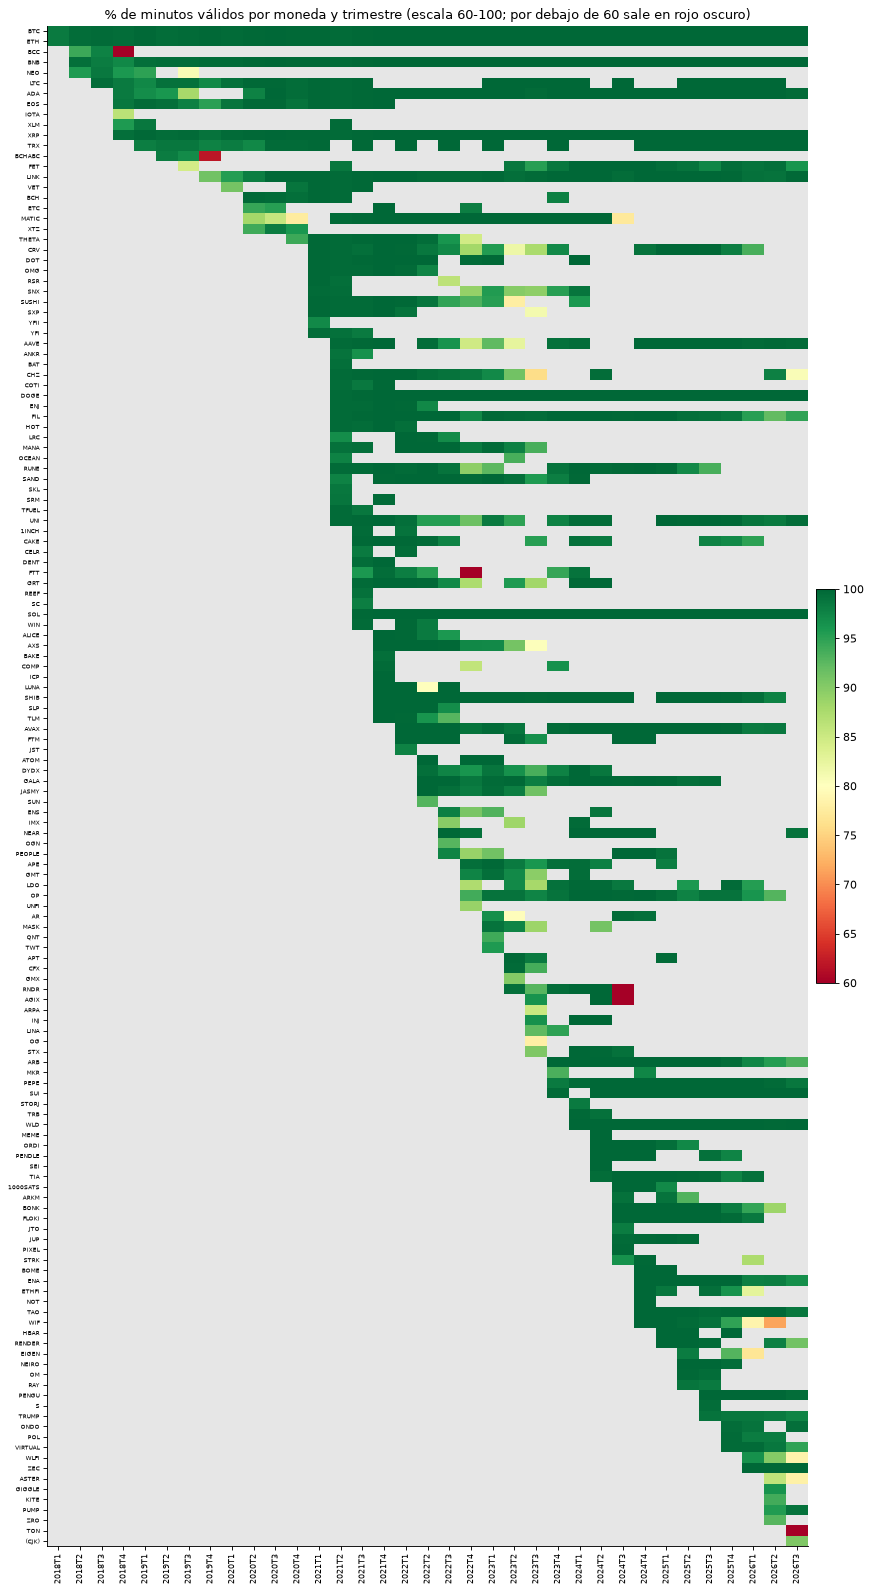

In [28]:
# Mapa moneda x trimestre del % de minutos válidos. Gris = la moneda no estaba en el universo ese trimestre.
valid_map = overview.quality["valid_pct"].unstack("period_start")
first_quarter = valid_map.notna().to_numpy().argmax(axis=1)
ordered = [
    s for _, s in sorted(zip(first_quarter, valid_map.index))
]  # por primer trimestre y nombre
valid_map = valid_map.loc[ordered]

cmap = plt.get_cmap("RdYlGn").with_extremes(bad="#e6e6e6")
fig, ax = plt.subplots(figsize=(11, 20))
image = ax.imshow(
    valid_map.to_numpy(), aspect="auto", cmap=cmap, vmin=60, vmax=100, interpolation="nearest"
)
ax.set_yticks(range(len(valid_map)), [plain(s) for s in valid_map.index], fontsize=5.5)
ax.set_xticks(
    range(valid_map.shape[1]), [qlabel(q) for q in valid_map.columns], rotation=90, fontsize=7
)
ax.grid(False)
ax.set_title(
    "% de minutos válidos por moneda y trimestre (escala 60-100; por debajo de 60 sale en rojo oscuro)"
)
fig.colorbar(image, ax=ax, fraction=0.025, pad=0.01)
plt.tight_layout()
plt.show()

**Interpretación.** El mapa es casi todo verde oscuro (97-100 % de minutos válidos): las monedas grandes (BTC, ETH, BNB, ADA, XRP, SOL…) tienen prácticamente todos sus minutos. Las manchas claras o rojas se concentran en tres sitios: **(1) 2022T4-2023T3**, con FTT al 45,4 % en 2022T4 (el trimestre de su colapso) y varias altcoins entre el 75 % y el 90 %; **(2) 2026T1-T3**, con WIF, EIGEN, ASTER, WLFI y CHZ; y **(3) los pares que dejan de cotizar**: BCC 2018T4, BCHABC 2019T4, RNDR y AGIX en 2024T3 y TON en 2026T3 (rojo oscuro). Las casillas **grises** no son datos malos sino monedas que no estaban en el universo ese trimestre: las monedas van ordenadas de arriba abajo por el trimestre en que entran por primera vez, así que se ve cómo el universo incorpora monedas nuevas (la zona gris de abajo a la izquierda, antes de que entren) y cómo salen otras (la zona gris de arriba a la derecha, tras su último trimestre). La moneda de nombre chino se rotula `(CJK)` porque la fuente no dibuja esos caracteres.

### 4.2 Resumen por trimestre y peores casos

In [29]:
# Resumen por trimestre de la calidad: media/mínimo de minutos válidos y % de retornos y volatilidad vacíos.
quality = overview.quality
by_q = quality.groupby("period_start")
summary_q = pd.DataFrame(
    {
        "monedas": by_q.size(),
        "% válido (media)": by_q["valid_pct"].mean(),
        "% válido (mediana)": by_q["valid_pct"].median(),
        "% válido (mínimo)": by_q["valid_pct"].min(),
        "% return NaN (media)": by_q["return_nan_pct"].mean(),
        "% realized_vol NaN (media)": by_q["realized_vol_nan_pct"].mean(),
    }
)
summary_q.index = [qlabel(q) for q in summary_q.index]
display(summary_q)

,monedas,% válido (media),% válido (mediana),% válido (mínimo),% return NaN (media),% realized_vol NaN (media)
2018T1,2,98.31404,98.31404,98.31404,1.68904,1.79707
2018T2,5,97.59295,99.31471,94.09264,3.87531,6.41071
2018T3,6,98.86612,98.98702,97.70833,1.82719,1.57470
2018T4,11,92.44716,98.34994,48.02310,9.54511,11.35801
2019T1,10,98.38488,98.98997,94.96991,2.78704,3.08079
2019T2,9,98.78527,99.33913,95.96993,1.77215,2.04874
2019T3,11,94.91628,98.60809,80.76389,8.46529,15.54993
2019T4,9,93.47247,97.76193,61.91501,8.28368,10.40073
2020T1,9,97.86867,99.12241,91.05464,3.43559,5.44304
2020T2,13,97.49137,99.69017,88.02350,4.26071,6.73453


**Interpretación.** Desde 2021T2 la calidad media es muy alta (≥ 99 % de minutos válidos) salvo en trimestres concretos: 2022T2 98,6 % (LUNA), 2022T3 97,9 %, **2022T4 94,1 %** (FTT al 45,4 %), 2023T1 98,05 %, **2023T2 95,8 % y 2023T3 93,6 %** (en 2023T3 la mediana también baja, a 95,5 %: no es un par roto sino mucho mercado con minutos sin operaciones), 2023T4 98,66 %, **2024T3 94,7 %** (la media la arrastran AGIX, RNDR y MATIC: la mediana sigue en 99,97 %) y **2026T1-T3 con 96,9 %, 96,7 % y 93,3 %** (en 2026T3 por TON al 0 % y por las ilíquidas). Antes de 2021T1 hay 2-14 monedas y las cifras bailan más (2018T4 tiene una moneda al 48 %). Fíjate también en que `realized_vol` queda vacía **casi el doble** que `return` en los trimestres malos (2023T3: 21,1 % frente a 11,2 %; 2022T4: 16,1 % frente a 9,3 %) y casi igual en los buenos: es el efecto de exigir el 80 % de cobertura en la ventana de 60 minutos.

In [30]:
# Los 15 pares-trimestre con menos minutos válidos y su % de NaN en cada feature.
worst = quality.sort_values("valid_pct").head(15).reset_index()
worst["trimestre"] = worst["period_start"].map(qlabel)
display(worst.set_index(["trimestre", "symbol"]).drop(columns="period_start"))

valid_pct  return_nan_pct  realized_vol_nan_pct  rel_volume_nan_pct  rel_trades_nan_pct
trimestre symbol                                                                                             
2026T3    TONUSDT       0.00000       100.00000             100.00000           100.00000           100.00000
2024T3    AGIXUSDT      0.13662        99.86338              99.85432            99.86338            99.86338
          RNDRUSDT     22.95969        77.04333              77.02823            77.04031            77.04031
2022T4    FTTUSDT      45.38421        57.45999              64.56144            54.61579            54.61579
2018T4    BCCUSDT      48.02310        52.97856              53.94550            51.97690            51.97690
2019T4    BCHABCUSDT   61.91501        39.00438              38.26766            38.08499            38.08499
2026T2    WIFUSDT      71.41941        42.59386              70.12668            31.84447            31.84447
2023T3    CHZUSDT      75.87183        38.72283              71.98973            24.12817            24.12817
2026T1    EIGENUSDT    76.84414        33.79630              54.52623            26.75772            26.75772
2024T3    MATICUSDT    77.30148        22.70758              22.68040            22.69852            22.69852
2020T4    MATICUSDT    77.59964        35.77672              68.09179            22.40036            22.40036
2023T2    SUSHIUSDT    77.86935        36.22176              69.64286            22.13065            22.13065
2023T3    OGUSDT       78.00800        34.66561              60.45139            22.17844            22.17844
2026T3    ASTERUSDT    78.24200        33.97569              59.40293            21.75800            21.75800
          WLFIUSDT     78.49940        34.09647              63.52204            21.50060            21.50060

**Interpretación.** Los peores pares-trimestre son o monedas que dejan de cotizar dentro de su trimestre (sección 3.3): TON (0 %) y AGIX (0,14 %), deslistadas, y RNDR (23,0 %, 2024T3), BCC (48,0 %, 2018T4) y BCHABC (61,9 %, 2019T4), que son cambios de símbolo (RNDR a RENDER; BCC y BCHABC a BCH); o una moneda rota que sigue cotizando (FTT, 45,4 % en 2022T4); o ilíquidas con 71-79 % de minutos válidos: WIF en 2026T2 (71,4 %), CHZ en 2023T3 (75,9 %), EIGEN en 2026T1 (76,8 %), MATIC en 2020T4, SUSHI, OG, ASTER y WLFI. (MATIC en 2024T3, 77,3 %, es otro cambio de símbolo, a POL.) En las ilíquidas el % de `return` vacío es **cerca de 1,6 veces el % de minutos sin operaciones** (WLFI: 21,5 % de minutos sin operaciones y 34,1 % de retornos vacíos; menos del doble porque algunos huecos son seguidos y comparten el retorno vacío) y el de `realized_vol` es aún mayor (63,5 %, por la regla del 80 %). `rel_volume` y `rel_trades` quedan vacíos solo en los minutos inválidos (21,5 % en WLFI).

### 4.3 Causas de hueco por trimestre

Descriptivo y *ex post* (D-17): suma de los slots de todas las monedas del trimestre, por causa, como % del total. `NOT_LISTED` y `NO_DATA` no aparecen porque el universo exige historia previa y un par sin velas en su rango sale como `DELISTED`.

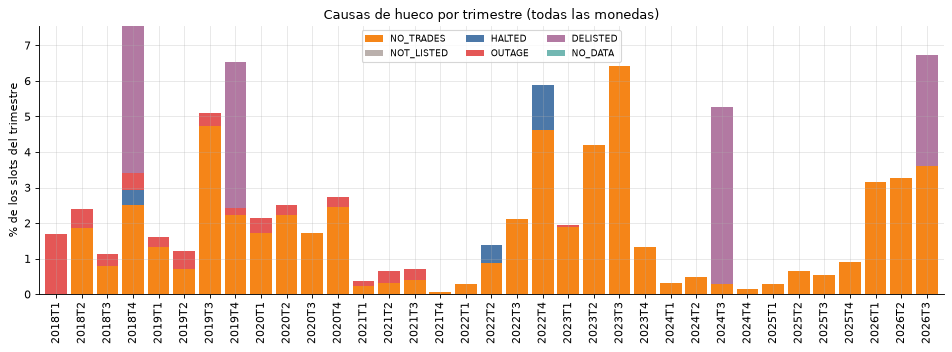

,VALID,NO_TRADES,NOT_LISTED,HALTED,OUTAGE,DELISTED,NO_DATA
2018T1,98.31,0.00,0.0,0.00,1.69,0.00,0.0
2018T4,92.45,2.50,0.0,0.44,0.48,4.14,0.0
2021T1,99.63,0.24,0.0,0.00,0.13,0.00,0.0
2022T2,98.61,0.89,0.0,0.50,0.00,0.00,0.0
2022T4,94.12,4.61,0.0,1.27,0.00,0.00,0.0
2023T2,95.79,4.21,0.0,0.00,0.00,0.00,0.0
2023T3,93.59,6.41,0.0,0.00,0.00,0.00,0.0
2024T3,94.73,0.28,0.0,0.00,0.00,4.99,0.0
2025T4,99.10,0.90,0.0,0.00,0.00,0.00,0.0
2026T1,96.85,3.15,0.0,0.00,0.00,0.00,0.0


,2018T1,2018T2,2018T3,2018T4,2019T1,2019T2,2019T3,2019T4,2020T1,2020T2,2020T4,2021T1,2021T2,2021T3,2023T1
OUTAGE,1.69,0.54,0.34,0.48,0.28,0.5,0.36,0.2,0.41,0.27,0.28,0.13,0.33,0.29,0.06


In [31]:
# % de slots por causa (suma de todas las monedas), apilado por trimestre. VALID no se dibuja.
causes_by_q = overview.gap_causes.groupby("period_start").sum()
share = causes_by_q.div(causes_by_q.sum(axis=1), axis=0) * 100
share.index = [qlabel(q) for q in share.index]

fig, ax = plt.subplots(figsize=(12, 4.5))
share.drop(columns="VALID").plot.bar(
    stacked=True,
    ax=ax,
    width=0.85,
    color=["#f58518", "#bab0ac", "#4c78a8", "#e45756", "#b279a2", "#72b7b2"],
)
ax.set_ylabel("% de los slots del trimestre")
ax.set_xlabel("")
ax.set_title("Causas de hueco por trimestre (todas las monedas)")
ax.legend(ncol=3, fontsize=8)
plt.tight_layout()
plt.show()

display(share.round(2).iloc[[0, 3, 12, 17, 19, 21, 22, 26, 31, 32, 34]])
# Trimestres con caídas de Binance (OUTAGE > 0), en % de los slots.
display(share.loc[share["OUTAGE"] > 0, ["OUTAGE"]].round(2).T)

**Interpretación.** `NO_TRADES` es la causa dominante casi siempre, de 0,07 % de los slots (2021T4) a **6,41 % (2023T3)**, con 4,61 % en 2022T4 y un 3,1-3,6 % en 2026T1-T3. `HALTED` solo aparece en 2018T4 (0,44 %), 2022T2 (0,50 %, la parada de LUNA) y 2022T4 (1,27 %). `OUTAGE` (caídas de Binance) vale 1,69 % en 2018T1 (con solo 2 monedas) y entre 0,13 % y 0,54 % en los demás trimestres hasta 2021T3, salvo 2020T3, donde no hay ninguna; vuelve de forma marginal en 2023T1 (0,06 %) y **no aparece desde 2023T2** (segunda tabla). `DELISTED` aparece solo en 2018T4 (4,14 %), 2019T4 (4,10 %), 2024T3 (4,99 %) y 2026T3 (3,12 %): son los deslistados de la sección 3.3. `NOT_LISTED` y `NO_DATA` valen 0: el universo exige historia previa. La mayor parte de lo que falta, por tanto, son **minutos sin operaciones**, en tramos cortos (secciones 2.3 y 4.5), no paradas largas.

### 4.4 Retornos vacíos a lo largo del tiempo

Esto es lo que verá el modelo: la parte de los retornos de 1 minuto que son `NaN`. También se enseña `realized_vol`, que por la regla del 80 % de cobertura (D-20) queda vacía **más a menudo** que el retorno en las monedas ilíquidas.

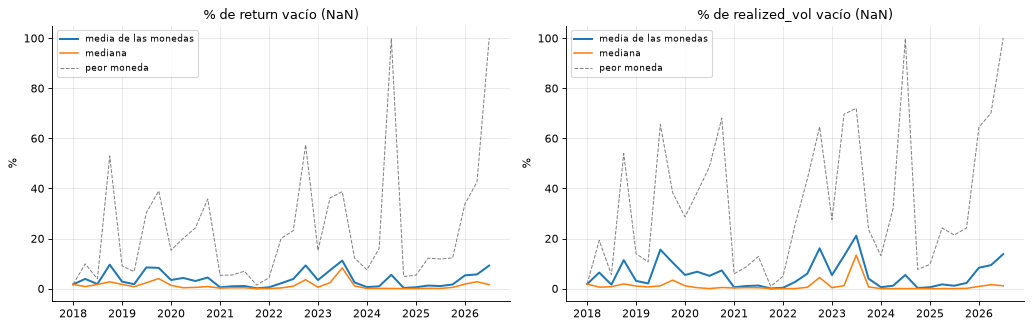

,return_nan_pct,realized_vol_nan_pct
2023T3,11.19694,21.13862
2018T4,9.54511,11.35801
2022T4,9.27640,16.07378
2019T3,8.46529,15.54993
2019T4,8.28368,10.40073
2023T2,7.32845,13.02900


Trimestres con mediana de retornos vacíos < 3 %: 32 de 35
Por encima del 3 %: {'2023T3': 8.3, '2019T4': 4.0, '2022T4': 3.6}
Media de retornos vacíos desde 2021T2: 3.4 % (mediana de los trimestres: 1.9 %)


In [32]:
# Evolución del % de NaN de return y de realized_vol: media, mediana y peor moneda de cada trimestre.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharex=True)
for ax, column, title in zip(
    axes, ["return_nan_pct", "realized_vol_nan_pct"], ["return", "realized_vol"]
):
    stats = quality.groupby("period_start")[column].agg(["mean", "median", "max"])
    ax.plot(stats.index, stats["mean"], label="media de las monedas", lw=1.8)
    ax.plot(stats.index, stats["median"], label="mediana", lw=1.4)
    ax.plot(stats.index, stats["max"], label="peor moneda", lw=0.9, ls="--", color="gray")
    ax.set_title(f"% de {title} vacío (NaN)")
    ax.set_ylabel("%")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# Los trimestres con más retornos vacíos de media (sin contar las monedas sin datos en todo el trimestre).
core = quality[quality["valid_pct"] > 1]
avg = core.groupby("period_start")[["return_nan_pct", "realized_vol_nan_pct"]].mean()
avg.index = [qlabel(q) for q in avg.index]
display(avg.sort_values("return_nan_pct", ascending=False).head(6))
# Cifras de la interpretación: mediana de las monedas por trimestre y media desde 2021T2.
median_q = quality.groupby("period_start")["return_nan_pct"].median()
print(
    f"Trimestres con mediana de retornos vacíos < 3 %: {int((median_q < 3).sum())} de {len(median_q)}"
)
print(
    "Por encima del 3 %:",
    {
        qlabel(q): round(v, 1)
        for q, v in median_q[median_q >= 3].sort_values(ascending=False).items()
    },
)
mean_q = quality.groupby("period_start")["return_nan_pct"].mean()
since_2021q2 = mean_q[mean_q.index >= pd.Timestamp("2021-04-01", tz="UTC")]
print(
    f"Media de retornos vacíos desde 2021T2: {since_2021q2.mean():.1f} % "
    f"(mediana de los trimestres: {since_2021q2.median():.1f} %)"
)

**Interpretación.** La mediana de las monedas (naranja) queda por debajo del 3 % en 32 de los 35 trimestres: la moneda típica tiene pocos huecos casi siempre. Las tres excepciones son 2023T3 (8,3 %), 2019T4 (4,0 %) y 2022T4 (3,6 %). La media (azul) sube por unas pocas monedas muy huecas, y la peor moneda (gris discontinua) llega al 99,9 % en 2024T3 (AGIX) y al 100 % en 2026T3 (TON). La media de retornos vacíos desde 2021T2 es del 3,4 % (1,9 % si se toma la mediana de los trimestres), con un máximo de **11,2 % en 2023T3**. En `realized_vol` el efecto del 80 % de cobertura se nota en los trimestres malos (2023T3: 21,1 % frente a 11,2 %). La tabla ordena los trimestres por % de retornos vacíos sin contar las monedas con casi ningún minuto válido: 2023T3, 2018T4, 2022T4, 2019T3, 2019T4 y 2023T2 son los peores.

### 4.5 Casos destacados

- **LUNAUSDT 2022T2:** la parada de mayo (sección 2.2).
- **Iliquidez de 2026T3:** WLFI, ASTER y CHZ, con muchos minutos sin operaciones (no son huecos de la caché sino minutos en que nadie operó); la mayoría en tramos de un minuto, pero con rachas de hasta 24 (tabla de la celda siguiente).
- **Sin datos:** `TONUSDT` en 2026T3 y `AGIXUSDT` en 2024T3 (deslistadas dentro de su trimestre).

In [33]:
# Monedas ilíquidas de 2026T3 y casos extremos: minutos válidos, NO_TRADES y retornos/volatilidad vacíos.
q26 = pd.Timestamp("2026-07-01", tz="UTC")
cases = quality.xs(q26, level="period_start").join(
    overview.gap_causes.xs(q26, level="period_start")[["NO_TRADES", "DELISTED"]]
)
cases["% NO_TRADES"] = 100 * cases["NO_TRADES"] / overview.periods.loc[q26, "n_rows"]
display(
    cases.sort_values("valid_pct").head(8)[
        ["valid_pct", "% NO_TRADES", "return_nan_pct", "realized_vol_nan_pct", "rel_volume_nan_pct"]
    ]
)

# Comparación con una moneda líquida del mismo trimestre.
display(
    cases.loc[
        ["BTCUSDT", "ETHUSDT", "SOLUSDT"],
        [
            "valid_pct",
            "% NO_TRADES",
            "return_nan_pct",
            "realized_vol_nan_pct",
            "rel_volume_nan_pct",
        ],
    ]
)
# Longitud de los tramos seguidos de minutos sin operaciones de las tres más ilíquidas.
runs_26 = gap_runs(
    classify_klines(["WLFIUSDT", "ASTERUSDT", "CHZUSDT"], "1m", ms("2026-07-01"), ms("2026-10-01"))
)
no_trades_runs = runs_26[runs_26["cause"] == "NO_TRADES"].groupby("symbol")["n_slots"]
display(
    pd.DataFrame(
        {
            "tramos": no_trades_runs.size(),
            "minutos en total": no_trades_runs.sum(),
            "mediana (min)": no_trades_runs.median(),
            "máximo (min)": no_trades_runs.max(),
            "% de tramos de 1 minuto": 100 * no_trades_runs.apply(lambda s: (s == 1).mean()),
        }
    )
)

,valid_pct,% NO_TRADES,return_nan_pct,realized_vol_nan_pct,rel_volume_nan_pct
symbol,,,,,
TONUSDT,0.00000,0.00000,100.00000,100.00000,100.00000
ASTERUSDT,78.24200,21.75800,33.97569,59.40293,21.75800
WLFIUSDT,78.49940,21.50060,34.09647,63.52204,21.50060
CHZUSDT,80.58726,19.41274,32.13844,62.64719,19.41274
币安人生USDT,90.34420,9.65580,16.28019,29.76827,9.65580
RENDERUSDT,91.09677,8.90323,15.39553,31.41153,8.90323
ARBUSDT,93.36277,6.63723,11.68554,24.07533,6.63723
VIRTUALUSDT,94.76072,5.23928,9.31688,16.59194,5.23928


,valid_pct,% NO_TRADES,return_nan_pct,realized_vol_nan_pct,rel_volume_nan_pct
symbol,,,,,
BTCUSDT,100.0,0.0,0.0,0.0,0.0
ETHUSDT,100.0,0.0,0.0,0.0,0.0
SOLUSDT,100.0,0.0,0.0,0.0,0.0


,tramos,minutos en total,mediana (min),máximo (min),% de tramos de 1 minuto
symbol,,,,,
ASTERUSDT,16185,28824,1.0,24,61.23571
CHZUSDT,16859,25719,1.0,15,69.06697
WLFIUSDT,16687,28484,1.0,18,63.30677


**Interpretación.** En 2026T3, ASTER (78,2 % válido), WLFI (78,5 %) y CHZ (80,6 %) tienen entre el **19 % y el 22 % de minutos sin operaciones**: por D-18 eso deja `NaN` entre el 32 % y el 34 % de sus retornos y entre el 59 % y el 64 % de su `realized_vol`. `币安人生` (90,3 %), RENDER (91,1 %), ARB (93,4 %) y VIRTUAL (94,8 %) están mejor, pero también con entre el 5 % y el 10 % de minutos sin operaciones. Los minutos sin operaciones de ASTER, WLFI y CHZ no son todos sueltos: entre el 61 % y el 69 % de sus tramos duran un solo minuto (mediana 1), pero hay rachas de hasta 24 minutos en ASTER, 18 en WLFI y 15 en CHZ (última tabla). Frente a ellas, BTC, ETH y SOL tienen el **100 %** de minutos válidos y 0 % de `NaN`. Efecto práctico: en una estimación a 1 minuto entre BTC y WLFI, un tercio de los retornos de WLFI no existe y buena parte del resto son ceros (sección 2.3), y esa iliquidez puede bajar la correlación (sección 8.1, solo descriptiva). TON aparece con 0 % porque se deslistó.

## 5. Las cuatro features

Las cuatro (`return`, `realized_vol`, `rel_volume`, `rel_trades`) están agrupadas por trimestre con **todos los valores no `NaN` de todas las monedas**. Las bandas son cuantiles de esa mezcla de monedas; no es la distribución de una moneda. `realized_vol` y `rel_*` dependen del nivel de actividad de cada trimestre.

### 5.1 Distribución y evolución

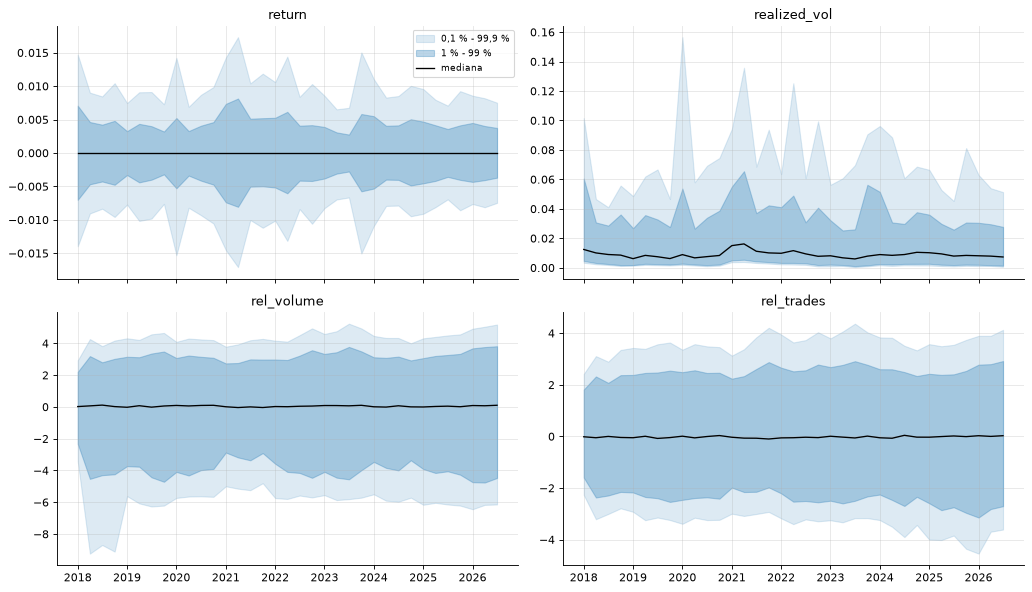

q0.001    q0.01    q0.25     q0.5    q0.75    q0.99   q0.999
period_start              feature                                                                    
2025-01-01 00:00:00+00:00 return       -0.00910 -0.00454 -0.00082  0.00000  0.00081  0.00469  0.00956
                          realized_vol  0.00153  0.00269  0.00748  0.01021  0.01390  0.03606  0.06652
                          rel_volume   -6.15715 -3.90758 -0.81401 -0.00438  0.80959  3.06944  4.31571
                          rel_trades   -4.00048 -2.59168 -0.61366 -0.03013  0.57815  2.42731  3.57728
2026-07-01 00:00:00+00:00 return       -0.00747 -0.00370 -0.00051  0.00000  0.00050  0.00375  0.00752
                          realized_vol  0.00068  0.00143  0.00468  0.00732  0.01099  0.02777  0.05137
                          rel_volume   -6.13744 -4.47074 -0.90660  0.10318  1.10574  3.81694  5.18101
                          rel_trades   -3.60916 -2.70406 -0.68370  0.02811  0.74636  2.92170  4.13103

In [34]:
# Mediana y bandas (1-99 % y 0,1-99,9 %) de cada feature, trimestre a trimestre.
fq = overview.feature_quantiles
fig, axes = plt.subplots(2, 2, figsize=(13, 7.5), sharex=True)
for ax, feature in zip(axes.ravel(), ["return", "realized_vol", "rel_volume", "rel_trades"]):
    table = fq.xs(feature, level="feature")
    x = table.index
    ax.fill_between(
        x, table["q0.001"], table["q0.999"], alpha=0.15, color="tab:blue", label="0,1 % - 99,9 %"
    )
    ax.fill_between(
        x, table["q0.01"], table["q0.99"], alpha=0.30, color="tab:blue", label="1 % - 99 %"
    )
    ax.plot(x, table["q0.5"], color="black", lw=1.2, label="mediana")
    ax.set_title(feature)
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

# Valores concretos de 2025T1 y 2026T3.
rows_show = [
    (pd.Timestamp(q, tz="UTC"), f)
    for q in ("2025-01-01", "2026-07-01")
    for f in ("return", "realized_vol", "rel_volume", "rel_trades")
]
display(fq.loc[rows_show])

**Interpretación.** `return`: la mediana es exactamente 0 en todos los trimestres y la banda del 1 %-99 % se mueve entre ±0,0028 (2023T3) y ±0,0081 (2021T2); en 2025T1 es de −0,0045 a +0,0047 y en 2026T3 de −0,0037 a +0,0037. `realized_vol`: la mediana va de **0,0060 (2023T3) a 0,0162 (2021T2)**, con una cola alta que llega a 0,157 en 2020T1 (un trimestre que incluye marzo de 2020). `rel_volume` y `rel_trades` están centrados en 0 (medianas entre −0,04 y +0,11 para `rel_volume`), que es lo que cabe esperar de una variable relativa a su propio pasado, y su dispersión crece en 2026: el percentil 1 de `rel_volume` pasa de −3,91 (2025T1) a −4,47 (2026T3) y el 99 de 3,07 a 3,82, coherente con más iliquidez. `rel_trades` tiene colas menos anchas que `rel_volume` (percentiles 1 y 99 de −2,59 y 2,43 en 2025T1, frente a −3,91 y 3,07): el número de operaciones varía menos que el volumen.

### 5.2 Colas de los retornos trimestre a trimestre

`tail_report` por moneda y trimestre. Se muestra la **mediana entre monedas** de la curtosis en exceso (una normal vale 0), del máximo |z| y de la parte de la suma de cuadrados que aporta el 0,1 % de retornos más grandes. Son descriptivos: no se usan como filtro (D-22).

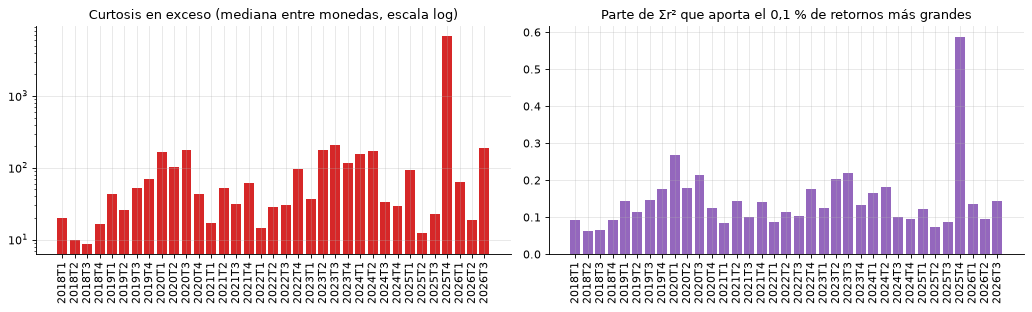

,kurtosis,max_abs_z,top_var_share
2025T4,6823.34986,152.01117,0.58823
2023T3,209.91610,55.17500,0.21981
2026T3,186.33613,61.62823,0.14370
2020T3,177.18999,51.60883,0.21325
2023T2,175.20126,52.88136,0.20386


,kurtosis,max_abs_z,top_var_share
2021T2,51.54488,34.95100,0.14283
2022T2,27.98678,27.67997,0.11343
2025T1,91.92465,47.81803,0.12296
2025T4,6823.34986,152.01117,0.58823
2026T3,186.33613,61.62823,0.14370


In [35]:
# Mediana entre monedas de las medidas de cola, por trimestre.
tails = overview.tails
tail_q = tails.groupby("period_start")[["kurtosis", "max_abs_z", "top_var_share"]].median()
tail_q.index = [qlabel(q) for q in tail_q.index]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(tail_q.index, tail_q["kurtosis"], color="tab:red")
axes[0].set_yscale("log")
axes[0].set_title("Curtosis en exceso (mediana entre monedas, escala log)")
axes[0].tick_params(axis="x", labelrotation=90)
axes[1].bar(tail_q.index, tail_q["top_var_share"], color="tab:purple")
axes[1].set_title("Parte de Σr² que aporta el 0,1 % de retornos más grandes")
axes[1].tick_params(axis="x", labelrotation=90)
plt.tight_layout()
plt.show()

display(tail_q.sort_values("kurtosis", ascending=False).head(5))
display(tail_q.loc[["2021T2", "2022T2", "2025T1", "2025T4", "2026T3"]])

**Interpretación.** La curtosis mediana es alta casi siempre: de **8,7 (2018T3, el mínimo) a 210 (2023T3)**, con una mediana de los trimestres de 44. El 0,1 % de retornos más grandes aporta entre el 6,3 % (2018T2) y el 26,9 % (2020T1) de la suma de cuadrados, con una mediana del 12,5 %. **2025T4 se sale de la escala**: curtosis mediana de 6 823, máximo |z| mediano de 152 y el 58,8 % de la suma de cuadrados en el 0,1 % de retornos (un trimestre normal como 2025T1 da 92, 48 y 12,3 %). Cuidado: la escala de la izquierda es logarítmica. Tras 2025T4, los de mayor curtosis son 2023T3 (210), 2026T3 (186), 2020T3 (177) y 2023T2 (175): no es un fenómeno de un solo trimestre.

### 5.3 Un solo minuto puede mover un trimestre: 2025T4

El trimestre 2025T4 sobresale en las medidas de cola. Se busca el minuto con el retorno más extremo y se mide cuánto cambia la correlación cruda **solo para ilustrar la sensibilidad** (es un descriptivo; no se recorta ni se elimina nada del panel, D-22).

In [36]:
# Minuto con el retorno absoluto más grande de 2025T4 y cuántas monedas se mueven a la vez.
r4 = read_panel("2025-10-01", features=["return"]).features["return"]
worst_minute = r4.abs().max(axis=1).idxmax()
at_minute = r4.loc[worst_minute].dropna().sort_values()
print("Minuto con el retorno más extremo:", worst_minute.strftime("%Y-%m-%d %H:%M UTC"))
print(
    f"Monedas con |retorno| > 5 % en ese minuto: {int((at_minute.abs() > 0.05).sum())} de {len(at_minute)}"
)
display(pd.concat([at_minute.head(5), at_minute.tail(3)]).to_frame("retorno log del minuto"))

# Correlación cruda del trimestre con y sin ese minuto (solo para medir la sensibilidad).
rows = {}
for label, frame in {
    "todos los minutos": r4,
    "sin ese minuto": r4.drop(index=worst_minute),
}.items():
    summ, eig, _ = summarize_correlation(raw_correlation(frame), label=label)
    rows[label] = {
        "correlación media": summ["pair_mean"],
        "% pares > 0,5": summ["pairs_above_high_pct"],
        "1.er componente": eig[0],
        "2.º componente": eig[1],
    }
display(pd.DataFrame(rows).T)

Minuto con el retorno más extremo: 2025-10-10 21:20 UTC
Monedas con |retorno| > 5 % en ese minuto: 35 de 40


,retorno log del minuto
ETHFIUSDT,-0.83195
TRUMPUSDT,-0.80301
LDOUSDT,-0.62710
ENAUSDT,-0.56365
SUIUSDT,-0.52593
ETHUSDT,-0.01387
SOLUSDT,-0.00205
TRXUSDT,-0.00093


,correlación media,"% pares > 0,5",1.er componente,2.º componente
todos los minutos,0.56020,68.46154,0.58530,0.06012
sin ese minuto,0.52725,60.76923,0.55586,0.06715


**Interpretación.** El retorno más extremo de 2025T4 es el del **10-oct-2025 a las 21:20 UTC**: 35 de las 40 monedas se mueven más de un 5 % (en log-retorno) en ese mismo minuto. ETHFI cae un log-retorno de −0,83 (el precio se divide por 2,3), TRUMP −0,80, LDO −0,63, ENA −0,56… mientras ETH (−0,014), SOL (−0,002) y TRX (−0,001) casi no se mueven. (Por conocimiento general, no verificado aquí, es el día de la caída masiva del mercado cripto.) **Un único minuto de 132 480 mueve la foto del trimestre**: quitándolo, la correlación media entre pares baja de 0,560 a 0,527, el % de pares > 0,5 de 68,5 % a 60,8 % y el 1.er componente de 58,5 % a 55,6 %. En cambio, el 2.º componente no se debe a ese minuto (6,0 % con él y 6,7 % sin él, frente al 2-3 % habitual): hay algo más en 2025T4. Por eso D-22 no recorta nada y por eso hay que hacer análisis de sensibilidad (no filtrar a ciegas).

## 6. Horizontes de 5, 15 y 60 minutos

Las barras de 5/15/60 minutos se construyen **desde el minuto** (D-23): una barra es válida si su último minuto es válido y al menos el 80 % de sus minutos lo son. Como `panel.valid` va indexado al **cierre** (D-19), la función `bar_validity_pct` lo pasa a aperturas (cambiar la etiqueta de cada fila no mueve ningún dato en el tiempo) y recorta a barras completas alineadas al reloj antes de llamar a `resample_validity`.

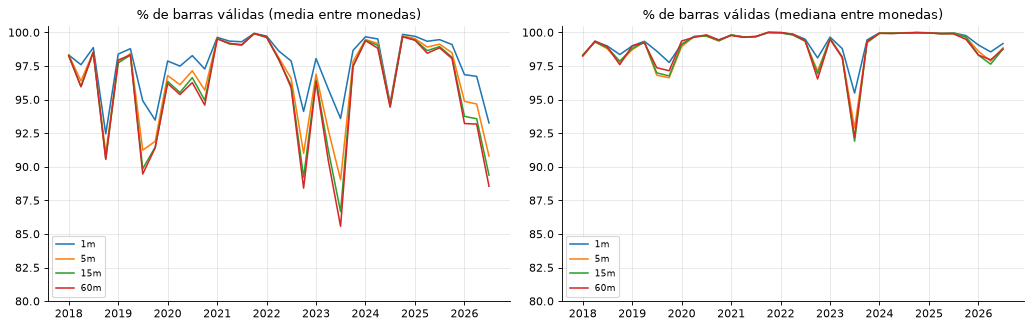

,1m,5m,15m,60m,pérdida 1m -> 60m (puntos)
2018T1,98.31404,98.31012,98.28684,98.23993,0.07412
2018T4,92.44716,91.00139,90.59408,90.54661,1.90055
2021T1,99.63349,99.55153,99.54139,99.51256,0.12093
2022T2,98.60928,98.10709,97.94247,98.01306,0.59622
2022T4,94.11638,90.99660,89.22517,88.40621,5.71017
2023T2,95.79027,92.75404,91.26159,90.48328,5.30699
2023T3,93.58911,89.03378,86.65978,85.56978,8.01933
2024T3,94.73111,94.56463,94.49015,94.43362,0.29749
2025T4,99.09600,98.48151,98.15168,98.05052,1.04547
2026T1,96.85361,94.86776,93.74957,93.21561,3.63800


Pérdida media 1m -> 60m desde 2021T2: 1.87 puntos


In [37]:
# % de barras válidas por horizonte: media entre las monedas de cada trimestre.
bv = overview.bar_validity
bv_mean = bv.groupby("period_start").mean()
bv_median = bv.groupby("period_start").median()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharex=True)
for column in bv_mean.columns:
    axes[0].plot(bv_mean.index, bv_mean[column], label=column, lw=1.4)
    axes[1].plot(bv_median.index, bv_median[column], label=column, lw=1.4)
axes[0].set_title("% de barras válidas (media entre monedas)")
axes[1].set_title("% de barras válidas (mediana entre monedas)")
for ax in axes:
    ax.set_ylim(80, 100.5)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

table = bv_mean.copy()
table.index = [qlabel(q) for q in table.index]
table["pérdida 1m -> 60m (puntos)"] = table["1m"] - table["60m"]
display(table.iloc[[0, 3, 12, 17, 19, 21, 22, 26, 31, 32, 34]])
print(
    "Pérdida media 1m -> 60m desde 2021T2:",
    round(table["pérdida 1m -> 60m (puntos)"].iloc[13:].mean(), 2),
    "puntos",
)

**Interpretación.** El % de barras válidas baja al alargar el horizonte, porque una barra necesita muchos minutos válidos y que el último lo sea. En los trimestres buenos la pérdida es mínima (2021T1: 0,12 puntos entre 1 y 60 minutos; 2022T2: 0,60; 2025T4: 1,05) y en los malos es grande: **2023T3 pasa de 93,6 % (1 min) a 85,6 % (60 min), 8,0 puntos**; 2022T4 pierde 5,7, 2023T2 5,3, 2026T3 4,7 (93,3 % → 88,6 %) y 2026T1 3,6. La pérdida media de 1 a 60 minutos desde 2021T2 es de **1,87 puntos** (97,9 % → 96,0 %). El caso de 2024T3 es distinto: casi no hay diferencia (94,7 % → 94,4 %) porque su pérdida son bloques largos de pares deslistados (AGIX, RNDR, MATIC), no minutos sueltos, y un bloque no se «agrava» al agregar. A 5 y 15 minutos la pérdida queda en un punto intermedio (en 2023T3, 89,0 % y 86,7 %). En la figura de la izquierda se ve que la media cae más que la mediana, porque son pocas monedas las que sufren.

## 7. El contrato en los 35 trimestres

`validate_panel` se ejecuta al construir y al cargar cada panel (D-29). Aquí se anota el resultado de cada uno y el tamaño que tiene.

In [38]:
# Resultado del contrato por trimestre (validate_panel ya se ejecutó al cargar cada panel).
periods = overview.periods.copy()
periods.index = [qlabel(q) for q in periods.index]
print(f"Paneles que cumplen el contrato: {int(periods['contract_ok'].sum())} de {len(periods)}")
print(
    f"Filas totales: {periods['n_rows'].sum():,} | celdas moneda-minuto: {(periods['n_rows'] * periods['n_symbols']).sum():,}"
)
display(
    periods[["n_rows", "n_symbols", "n_features", "contract_ok"]].iloc[
        [0, 1, 12, 13, 22, 23, 33, 34]
    ]
)
assert periods["contract_ok"].all(), periods.loc[~periods["contract_ok"], "contract_error"]

Paneles que cumplen el contrato: 35 de 35
Filas totales: 4,600,800 | celdas moneda-minuto: 130,947,840


,n_rows,n_symbols,n_features,contract_ok
2018T1,129600,2,4,True
2018T2,131040,5,4,True
2021T1,129600,21,4,True
2021T2,131040,40,4,True
2023T3,132480,40,4,True
2023T4,132480,35,4,True
2026T2,131040,38,4,True
2026T3,132480,32,4,True


**Interpretación.** **Los 35 paneles cumplen el contrato** (35 de 35; si alguno fallara la celda se detendría en el `assert`). Entre todos hay 4 600 800 filas de minuto (de 129 600 a 132 480 por trimestre, según tenga 90 a 92 días) y 130 947 840 celdas moneda-minuto, es decir, unos 524 millones de valores de features (cuatro por celda). El tamaño va de 2 monedas (2018T1) a 40, siempre con las 4 features. Ojo con lo que dice y lo que no: el contrato solo comprueba el **significado** del panel (`NaN` en inválidos, sin puentear huecos, sin `inf`, volatilidad ≥ 0), no que los datos sean buenos; para eso están las secciones 4 a 6.

## 8. El factor común en el tiempo: correlación cruda trimestre a trimestre

La foto del «antes» de residualizar (MIAX-046/213), repetida en los 35 trimestres con el mismo método (Pearson por pares sobre `return` válido, `min_periods = 1000`). Para que sea comparable con la figura residualizada (MIAX-060) se mantienen las mismas cifras: correlación media entre pares, % de pares > 0,5, correlación con BTC y varianza del primer componente. Las monedas sin datos se apartan (MIAX-213). **Hasta 2021T1 el universo tiene entre 2 y 21 monedas**: las cifras de ese tramo (por ejemplo, 100 % de pares > 0,5 con solo 2 monedas en 2018T1) no son comparables con las de 40 monedas.

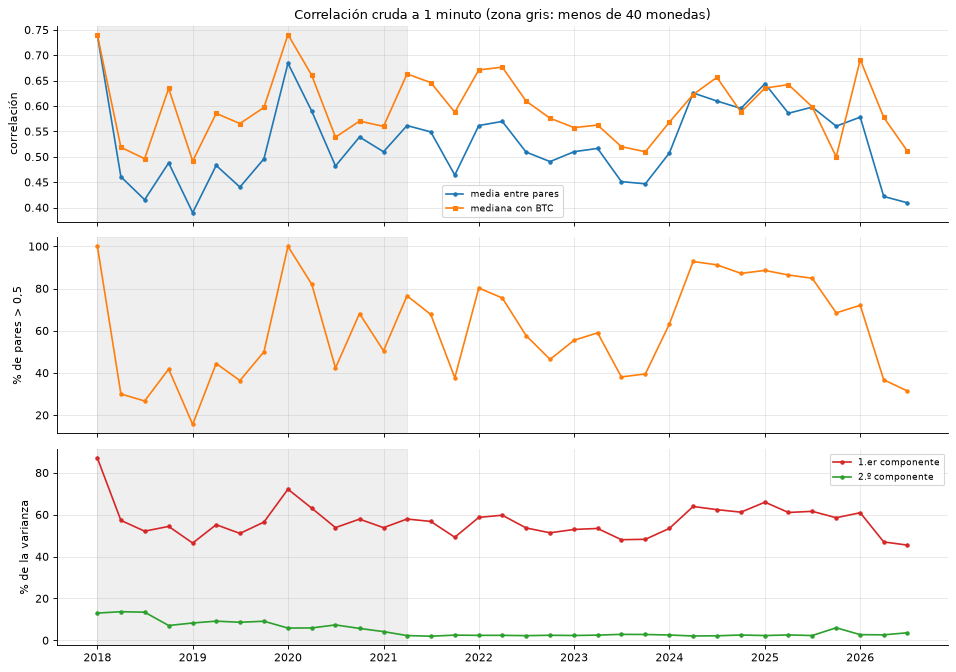

,n_symbols_in_universe,n_symbols_without_data,pair_mean,pairs_above_high_pct,factor_median,first_eigenvalue_share,second_eigenvalue_share
2021T1,21,0,0.50977,50.47619,0.55974,0.53787,0.04189
2021T2,40,0,0.56137,76.53846,0.66303,0.57909,0.02300
2021T3,40,0,0.54889,67.69231,0.64602,0.56765,0.01991
2021T4,40,0,0.46391,37.69231,0.58768,0.49213,0.02512
2022T1,40,0,0.56149,80.25641,0.67096,0.58686,0.02391
2022T2,40,0,0.56951,75.51282,0.67630,0.59723,0.02412
2022T3,40,0,0.50917,57.69231,0.60957,0.53657,0.02249
2022T4,40,0,0.49043,46.41026,0.57578,0.51336,0.02441
2023T1,38,0,0.50992,55.47653,0.55730,0.52938,0.02328
2023T2,40,0,0.51637,58.97436,0.56237,0.53409,0.02511


In [39]:
# Evolución del factor común: correlación media, % de pares > 0,5 y peso del 1.er componente.
corr_t = overview.correlation.copy()
# Una fila con `error` habría dejado un trimestre sin resumen (NaN) sin avisar: se exige que ninguno falle.
assert (overview.correlation["error"] == "").all(), overview.correlation.loc[
    overview.correlation["error"] != "", "error"
]
fig, axes = plt.subplots(3, 1, figsize=(12, 8.5), sharex=True)
axes[0].plot(corr_t.index, corr_t["pair_mean"], marker="o", ms=3, label="media entre pares")
axes[0].plot(corr_t.index, corr_t["factor_median"], marker="s", ms=3, label="mediana con BTC")
axes[0].set_ylabel("correlación")
axes[0].legend(fontsize=8)
axes[1].plot(corr_t.index, corr_t["pairs_above_high_pct"], marker="o", ms=3, color="tab:orange")
axes[1].set_ylabel("% de pares > 0,5")
axes[2].plot(
    corr_t.index,
    100 * corr_t["first_eigenvalue_share"],
    marker="o",
    ms=3,
    color="tab:red",
    label="1.er componente",
)
axes[2].plot(
    corr_t.index,
    100 * corr_t["second_eigenvalue_share"],
    marker="o",
    ms=3,
    color="tab:green",
    label="2.º componente",
)
axes[2].set_ylabel("% de la varianza")
axes[2].legend(fontsize=8)
for ax in axes:
    ax.axvspan(
        corr_t.index[0], pd.Timestamp("2021-04-01", tz="UTC"), color="gray", alpha=0.12
    )  # pocas monedas
axes[0].set_title("Correlación cruda a 1 minuto (zona gris: menos de 40 monedas)")
plt.tight_layout()
plt.show()

table = corr_t[
    [
        "n_symbols_in_universe",
        "n_symbols_without_data",
        "pair_mean",
        "pairs_above_high_pct",
        "factor_median",
        "first_eigenvalue_share",
        "second_eigenvalue_share",
    ]
].copy()
table.index = [qlabel(q) for q in table.index]
display(table.iloc[12:])

**Interpretación.** Desde 2021T1 (21 monedas) la correlación media entre pares oscila entre **0,409 (2026T3) y 0,644 (2025T1)**, con una mediana de los trimestres de 0,549; el 1.er componente explica entre el **45,5 % (2026T3) y el 66,0 % (2025T1)** de la varianza y el 2.º casi siempre entre el 2 % y el 4 % (la excepción es 2025T4, con 6,0 %; ver sección 5.3). El nivel no es estable: sube en 2024T2 (0,626 y 92,8 % de pares > 0,5) y se mantiene alto hasta 2026T1 (0,56 a 0,64), y **baja en 2026T2 y 2026T3 (0,422 y 0,409; 36,7 % y 31,4 % de pares > 0,5)**, los valores más bajos desde 2021. La correlación mediana con BTC va, desde 2021T2, de 0,50 (2025T4) a 0,69 (2026T1). **Antes de 2021T2 las cifras no son comparables**: el 0,739 y el 100 % de pares > 0,5 de 2018T1 es un único par (BTC-ETH), y el 0,684 de 2020T1 (100 % de pares > 0,5) sale de 9 monedas. En todos los trimestres desde 2021T1 un solo componente explica casi la mitad de la varianza o más (del 45,5 % al 66,0 %): es el «espejismo de factor» del README.

In [40]:
# Trimestres con monedas apartadas por no tener datos (MIAX-213) y resumen desde 2021T2 (40 monedas).
apart = corr_t[corr_t["n_symbols_without_data"] > 0][
    ["n_symbols_in_universe", "n_symbols_without_data", "symbols_without_data", "n_symbols"]
].copy()
apart.index = [qlabel(q) for q in apart.index]
display(apart)

recent = corr_t.iloc[12:]
print(
    "Desde 2021T1: correlación media entre pares "
    f"{recent['pair_mean'].min():.3f}-{recent['pair_mean'].max():.3f} (mediana {recent['pair_mean'].median():.3f}); "
    f"1.er componente {100 * recent['first_eigenvalue_share'].min():.1f} %-{100 * recent['first_eigenvalue_share'].max():.1f} %"
)

,n_symbols_in_universe,n_symbols_without_data,symbols_without_data,n_symbols
2024T3,40,1,AGIXUSDT,39
2026T3,32,1,TONUSDT,31


Desde 2021T1: correlación media entre pares 0.409-0.644 (mediana 0.549); 1.er componente 45.5 %-66.0 %


**Interpretación.** Solo dos trimestres tienen monedas apartadas por no tener datos suficientes: **2024T3** (`AGIXUSDT`, con 181 minutos válidos, por debajo de `min_periods = 1000`; quedan 39 monedas de 40) y **2026T3** (`TONUSDT`, 31 de 32). En ambos el límite del 5 % de pares ausentes no salta porque se aparta la moneda entera (MIAX-213); sin esa regla, el informe de 2026T3 fallaba. En el resumen desde 2021T1, la correlación media va de 0,409 a 0,644 (mediana 0,549) y el 1.er componente del 45,5 % al 66,0 %.

### 8.1 ¿Pesa la iliquidez en la correlación?

La correlación a 1 minuto de una moneda con muchos minutos sin operaciones puede salir más baja (el efecto Epps: un precio que se actualiza tarde parece reaccionar con retraso, y la correlación simultánea baja). Aquí solo se **mide** si ocurre: se llama *ilíquida* a la moneda con menos del 97 % de minutos válidos del trimestre y se compara la correlación media entre monedas líquidas con la de los pares que incluyen alguna ilíquida. Es descriptivo; no demuestra la causa.

**Alcance.** Este apartado es un análisis descriptivo **añadido** al ticket (MIAX-214 no lo pedía). El umbral del 97 % es arbitrario (por ejemplo, en 2023T3 marca 25 de las 40 monedas como ilíquidas) y la comparación no permite una conclusión causal. El estudio del efecto Epps y de la microestructura es el ticket MIAX-070.

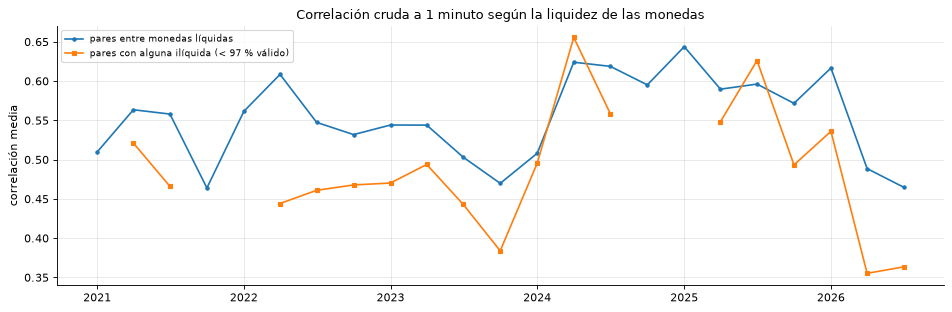

Trimestres desde 2021T1 con alguna ilíquida y alguna líquida: 18; en 16 es menor la correlación de los pares con ilíquida.
Diferencia media (líquidas menos con ilíquida): 0.065


,n_symbols_in_universe,n_illiquid,pair_mean,pair_mean_liquid,pair_mean_with_illiquid
2021T2,40,1,0.56137,0.56348,0.52113
2023T3,40,25,0.45099,0.50306,0.44289
2025T1,40,0,0.64381,0.64381,NaN
2026T1,40,11,0.57794,0.61658,0.53601
2026T2,38,11,0.42180,0.48855,0.35525
2026T3,32,10,0.40925,0.46486,0.36346


In [41]:
# Correlación media entre pares de monedas líquidas frente a pares con alguna ilíquida (valid_pct < 97 %).
liq = overview.correlation[
    [
        "n_symbols_in_universe",
        "n_illiquid",
        "pair_mean",
        "pair_mean_liquid",
        "pair_mean_with_illiquid",
    ]
].copy()

fig, ax = plt.subplots(figsize=(12, 4))
recent_liq = liq.iloc[12:]
ax.plot(
    recent_liq.index,
    recent_liq["pair_mean_liquid"],
    marker="o",
    ms=3,
    label="pares entre monedas líquidas",
)
ax.plot(
    recent_liq.index,
    recent_liq["pair_mean_with_illiquid"],
    marker="s",
    ms=3,
    label="pares con alguna ilíquida (< 97 % válido)",
)
ax.set_ylabel("correlación media")
ax.set_title("Correlación cruda a 1 minuto según la liquidez de las monedas")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# Desde 2021T1: en cuántos trimestres con alguna ilíquida es menor la correlación de sus pares.
with_illiquid = liq.iloc[12:].dropna(subset=["pair_mean_with_illiquid", "pair_mean_liquid"])
lower = int((with_illiquid["pair_mean_with_illiquid"] < with_illiquid["pair_mean_liquid"]).sum())
print(
    f"Trimestres desde 2021T1 con alguna ilíquida y alguna líquida: {len(with_illiquid)}; en {lower} es menor la correlación de los pares con ilíquida."
)
print(
    "Diferencia media (líquidas menos con ilíquida):",
    round((with_illiquid["pair_mean_liquid"] - with_illiquid["pair_mean_with_illiquid"]).mean(), 3),
)

liq.index = [qlabel(q) for q in liq.index]
display(liq.loc[["2021T2", "2023T3", "2025T1", "2026T1", "2026T2", "2026T3"]])

**Interpretación.** Desde 2021T1 hay 18 trimestres con monedas líquidas e ilíquidas a la vez, y en **16 de ellos** los pares que incluyen alguna ilíquida tienen **menos correlación** que los pares entre líquidas (la diferencia media es de 0,065). Ejemplos: 0,521 frente a 0,563 en 2021T2 (1 ilíquida), 0,443 frente a 0,503 en 2023T3 (25 ilíquidas), 0,536 frente a 0,617 en 2026T1, **0,355 frente a 0,489 en 2026T2 y 0,363 frente a 0,465 en 2026T3** (10-11 ilíquidas). Es compatible con el efecto Epps (precios que se actualizan tarde bajan la correlación simultánea) pero también con que las monedas ilíquidas sean más idiosincráticas: este notebook solo mide la diferencia, no la causa (MIAX-070). Dos matices: (1) en 2025T1 no hay ninguna ilíquida y la correlación entre líquidas es la más alta de la serie (0,644); (2) la bajada de 2026T2-T3 **no es solo iliquidez**: incluso entre líquidas la correlación baja de 0,617 (2026T1) a 0,489 y 0,465, aunque la composición de monedas también cambia.

## 9. Conclusiones para la Épica 3

Lo que sale de los 35 paneles, pensado para quien empieza la Épica 3 (residualización y lead-lag). Son hechos medidos aquí; las recomendaciones son propuestas, no decisiones.

1. **Los paneles están listos y cumplen el contrato.** 35 de 35 pasan `validate_panel`; 4 600 800 filas de minuto; 4 features y `valid`. Se leen de la caché en una fracción de segundo y son idénticos a reconstruirlos.
2. **Antes de 2021T2 hay muy pocas monedas (2 a 21).** Las cifras de 2018-2021T1 (correlaciones, causas de hueco, colas) salen de muy pocos pares y no son comparables con las de 40 monedas. Si el grafo se va a evaluar con muchas monedas, el tramo representativo empieza en 2021T2, como ya adelantaba `docs/datos/sesgo-supervivencia.md`.
3. **Los huecos no son aleatorios: se concentran en pocas monedas y en pocos trimestres.** La moneda típica tiene casi todos sus minutos (la mediana de retornos vacíos está por debajo del 3 % en 32 de 35 trimestres; las excepciones son 2023T3, con 8,3 %, 2019T4, con 4,0 %, y 2022T4, con 3,6 %), pero hay trimestres malos (2022T4, 2023T2-T3, 2026T1-T3) y monedas con un tercio de sus retornos vacíos (WLFI, ASTER, CHZ en 2026T3). A 1 minuto, esas monedas tienen muchos ceros reales y muchos vacíos: antes de estimar lead-lag con ellas hay que decidir qué hacer (la sección 8.1, un análisis descriptivo añadido con un umbral del 97 % arbitrario, mide que su correlación sale más baja, sin que eso permita una conclusión causal).
4. **Ojo con filtrar por calidad con datos del propio trimestre.** `valid_pct` y similares son descriptivos de todo el trimestre; usarlos para decidir qué monedas entran en un grafo del mismo trimestre sería mirar al futuro (D-17, D-30). Un filtro así debería basarse en el pasado (la ventana anterior o el train).
5. **Habrá columnas enteras o casi enteras `NaN`.** Solo `TONUSDT` en 2026T3 es una columna entera `NaN`; `AGIXUSDT` en 2024T3 es casi entera (181 minutos válidos, 99,86 % `NaN`). El código de B debe tolerar ambos casos (contrato §8): sin rellenar con 0 y sin que hagan fallar la estimación.
6. **Las colas existen y no se recortan.** Curtosis mediana de decenas a cientos y, en 2025T4, un solo minuto (10-oct-2025 21:20 UTC) que mueve 35 de 40 monedas y cambia la foto del trimestre (correlación media 0,560 → 0,527 sin ese minuto). Conviene hacer siempre el análisis de sensibilidad con límites ajustados en train (MIAX-056 y 079).
7. **Hay un factor común fuerte y cambiante.** Desde 2021T1 el 1.er componente explica entre el 45 % y el 66 % de la varianza y la correlación media entre pares va de 0,41 a 0,64: sin residualizar, casi cualquier par «parece» relacionado. Residualizar (MIAX-048 a 052) es imprescindible, y la figura residualizada (MIAX-060) debe repetir este mismo método y trimestre para compararse. La caída de 2026T2-T3 conviene vigilarla: no es solo iliquidez (8.1, descriptivo y sin conclusión causal).
8. **Horizontes.** A 60 minutos se pierden de media 1,9 puntos de barras válidas frente a 1 minuto, y hasta 8 en 2023T3; el 80 % de D-23 parece un compromiso razonable (en el ejemplo recupera casi todo lo que la regla estricta pierde).
9. **Features.** `realized_vol` queda vacía más que `return` en los trimestres malos (21 % frente a 11 % en 2023T3) por la regla del 80 %; `rel_volume` y `rel_trades` comparten gran parte de su información (la ablación de MIAX-127 decidirá si sobra una). Si se usa `realized_vol` como entrada, hay que contar con esos `NaN`.
10. **Lo que no se ha mirado aquí:** el efecto Epps y la microestructura como causa (la sección 8.1 es un análisis descriptivo añadido, con un umbral del 97 % arbitrario y sin conclusión causal; su estudio es MIAX-070); los universos semestral y anual (solo se ha usado el trimestral); y D-20 y D-23 siguen pendientes de validar con el tutor.